# CalicoST panel 18 (inclusion > 0.7): variogram matching

Spots in `data/h5ad/calicost/HT268B1-Th1K3Fc2U1Z1Bs1.h5ad` indexed by `configs/calicost/inclusion_gt0p7_qc60/panel18_HT268B1_Th1K3Fc2U1Z1Bs1_clone1_cluster0.indices.npy`. These are the panel 18 cells from the CalicoST clones with tumor inclusion above 0.7: clone 1 of HT268B1-Th1K3Fc2U1Z1Bs1, cluster 0. Coordinates stay in the stored `obsm["spatial"]` units. The matching experiment config records about 0.341 µm per native unit; this notebook does not rescale them. Expression is read from `layers["counts"]` and converted to natural-log CPM,

\[
X_{ig}=\log\left(1+10^6 C_{ig}/L_i\right),
\]

with \(L_i\) the spot's total UMI count across all genes in the retained panel. Ten genes are drawn without replacement from the genes whose log-CPM variance is positive (seed 42). Each selected gene then receives one independent permutation of its normalized expression across the fixed panel locations.

Pair distances are Euclidean. The cutoff is the exact 25th percentile of all unordered pairwise distances, and the bins follow geoR 1.9-5: 13 equal-width intervals ending at the largest observed distance strictly below that cutoff, left-closed and right-open, with the empty near-zero bin omitted. In every bin, \(\widehat\gamma_g(k)=\sum_{(i,j)\in N_k}(X_{ig}-X_{jg})^2/(2|N_k|)\).

## Adaptive matches for the ten genes

The bandwidth grid is \(nn \in \{0, 0.02, 0.05, 0.1, 0.2, \ldots, 0.9\}\). For \(nn>0\), \(h_i\) is the distance from spot \(i\) to its \(\lceil nn(N-1)\rceil\)-th other spot. Smoothing is a normalized Gaussian weighted average with locfit's factor 2.5, so the Gaussian standard deviation is \(h_i/2.5\). The \(nn=0\) candidate is the unsmoothed permutation.

**Unconstrained match.** As in the MERFISH notebook, regress the real variogram on the smoothed variogram with an intercept, form \(\sqrt{|b|}\,Y+\sqrt{|a|}\,R\), and choose \(nn\) by the empirical variogram SSE. Each gene uses a NumPy noise stream with seed 1, advanced across positive bandwidths. The selected field is then shifted and scaled to the real gene's mean and population standard deviation. The \(nn=0\) field is left unchanged.

**Variance-constrained match.** Standardize each gene to mean 0 and population variance 1. Fit \(a+b\widehat\gamma_Y(h)\) subject to \(a+b\mathrm{Var}(Y)=1\) and \(a,b\geq 0\), and choose \(nn\) by that constrained theoretical SSE. The surrogate is \(\sqrt{b}\,Y+\sqrt{a}\,R\) with one centered, unit-variance Gaussian column per gene (seed 62), reused across bandwidths. There is no final rescaling. The \(nn=0\) candidate stays the standardized permutation, \(a=0\), \(b=1\).

The comparison plot shows the two selected variograms with the real and permuted variograms on the standardized scale. The unconstrained curve is the final mean/SD-normalized variogram divided by the gene variance. The constrained curve is the realized variogram of the unscaled surrogate.

The four-column maps show the constrained surrogate \(\mu+sZ\), using the real gene's mean and population SD, so it shares the log-CPM color scale. Its own sample SD is left as realized.

## Smoother stability across genes

The last three figures in `variogram_matching.ipynb` are repeated for both fits. Every gene with positive log-CPM variance is standardized to mean 0 and population variance 1. One hundred independent permutations use the same adaptive grid. Distance bins stay fixed.

For each permutation and bandwidth, MSE is the mean squared error of the fitted variogram curve over the valid bins. The constrained curve uses \(a+b\mathrm{Var}(Y)=1\). The unconstrained curve is ordinary least squares with a free intercept and slope. In both versions, \(nn=0\) is the unsmoothed permutation and is scored by its own variogram, without a regression. The selected bandwidth minimizes that curve MSE. Each gene then contributes the variance of the selected \(nn\) across permutations, the average selected MSE, and its sparsity (panel spots with a positive count).


CalicoST panel 18, clone 1, inclusion > 0.7: 401 spots, 36601 genes, 20708 with positive variance.
Tumor proportion: min 0.701, median 0.838, max 1.000.
Selected genes: ZBTB41, TTC19, REN, AL049829.2, MTSS1, MTDH, ANXA2, PROX1-AS1, MORC1, CYP4F11


,gene,detected_spots,total_counts,log_CPM_variance
0,ZBTB41,148,216.0,3.902509
1,TTC19,208,358.0,4.576440
2,REN,1,1.0,0.036297
3,AL049829.2,1,1.0,0.030567
4,MTSS1,46,47.0,1.465927
5,MTDH,286,705.0,4.490780
6,ANXA2,380,2634.0,1.834565
7,PROX1-AS1,4,4.0,0.125070
8,MORC1,1,1.0,0.034433
9,CYP4F11,7,7.0,0.212601


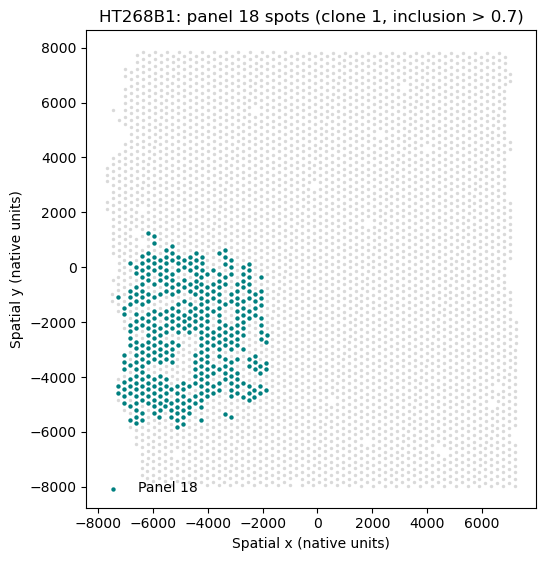

In [1]:
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

SEED = 42
N_GENES = 10
N_BINS = 13

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "data/h5ad/calicost/HT268B1-Th1K3Fc2U1Z1Bs1.h5ad").is_file()
)
h5ad_path = root / "data/h5ad/calicost/HT268B1-Th1K3Fc2U1Z1Bs1.h5ad"
index_path = (
    root / "configs/calicost/inclusion_gt0p7_qc60"
    / "panel18_HT268B1_Th1K3Fc2U1Z1Bs1_clone1_cluster0.indices.npy"
)
adata = ad.read_h5ad(h5ad_path)
indices = np.load(index_path)
if indices.ndim != 1 or len(np.unique(indices)) != len(indices):
    raise ValueError("Panel indices must be a one-dimensional set of unique rows.")
if indices.min() < 0 or indices.max() >= adata.n_obs:
    raise ValueError("Panel indices are outside the AnnData observation range.")

coords_all = np.asarray(adata.obsm["spatial"], dtype=np.float64)
if coords_all.shape != (adata.n_obs, 2):
    raise ValueError("Expected two-dimensional spatial coordinates.")
gene_names_all = adata.var_names.astype(str).to_numpy()
panel = adata[indices]
counts = panel.layers["counts"]
if sparse.issparse(counts):
    counts = counts.toarray()
counts = np.asarray(counts, dtype=np.float64)
coords = coords_all[indices]
clone = panel.obs["calicost_clone_label"].to_numpy()
tumor_proportion = panel.obs["calicost_tumor_proportion"].to_numpy(dtype=np.float64)
del adata, panel

if not np.all(clone == clone[0]):
    raise ValueError("Panel 18 is expected to contain a single CalicoST clone.")
if not np.isfinite(tumor_proportion).all() or np.min(tumor_proportion) <= 0.7:
    raise ValueError("Panel 18 spots are expected to have tumor inclusion above 0.7.")
if counts.ndim != 2 or counts.shape[0] != len(coords):
    raise ValueError("Panel counts do not match the retained spots.")
if not np.isfinite(counts).all() or np.any(counts < 0):
    raise ValueError("Expected finite, nonnegative raw counts.")
if not np.allclose(counts, np.round(counts)):
    raise ValueError("Expression does not appear to contain raw integer counts.")
library_size = counts.sum(axis=1)
keep = (library_size > 0) & np.isfinite(coords).all(axis=1)
if not np.all(keep):
    counts, coords, library_size = counts[keep], coords[keep], library_size[keep]
    clone, tumor_proportion = clone[keep], tumor_proportion[keep]
if len(coords) < 3:
    raise ValueError("Not enough panel spots.")

log_cpm_all = np.log1p(1e6 * counts / library_size[:, None])
gene_variance = log_cpm_all.var(axis=0, ddof=0)
usable = np.isfinite(gene_variance) & (gene_variance > 0)
if usable.sum() < N_GENES:
    raise ValueError("Not enough genes with positive log-CPM variance.")
selected_columns = np.random.default_rng(SEED).choice(
    np.flatnonzero(usable), size=N_GENES, replace=False
)
selected_genes = gene_names_all[selected_columns]
log_cpm = log_cpm_all[:, selected_columns]
selected_counts = counts[:, selected_columns]
del log_cpm_all

permuted_log_cpm = np.column_stack([
    np.random.default_rng(seed).permutation(log_cpm[:, j])
    for j, seed in enumerate(np.random.SeedSequence(SEED + 1).spawn(N_GENES))
])
assert np.array_equal(np.sort(log_cpm, axis=0), np.sort(permuted_log_cpm, axis=0))
n_cells, n_genes = log_cpm.shape
print(
    f"CalicoST panel 18, clone {clone[0]:g}, inclusion > 0.7: {n_cells} spots, "
    f"{counts.shape[1]} genes, {int(usable.sum())} with positive variance."
)
print(
    "Tumor proportion: "
    f"min {tumor_proportion.min():.3f}, median {np.median(tumor_proportion):.3f}, "
    f"max {tumor_proportion.max():.3f}."
)
print("Selected genes:", ", ".join(selected_genes))
display(pd.DataFrame({
    "gene": selected_genes,
    "detected_spots": (selected_counts > 0).sum(axis=0),
    "total_counts": selected_counts.sum(axis=0),
    "log_CPM_variance": log_cpm.var(axis=0, ddof=0),
}))

fig, ax = plt.subplots(figsize=(6.2, 6.2))
ax.scatter(coords_all[:, 0], coords_all[:, 1], s=6, c="0.85", linewidths=0, rasterized=True)
ax.scatter(coords[:, 0], coords[:, 1], s=10, c="teal", linewidths=0, rasterized=True, label="Panel 18")
ax.set_aspect("equal")
ax.legend(frameon=False, loc="best")
ax.set(
    title="HT268B1: panel 18 spots (clone 1, inclusion > 0.7)",
    xlabel="Spatial x (native units)",
    ylabel="Spatial y (native units)",
)
plt.show()


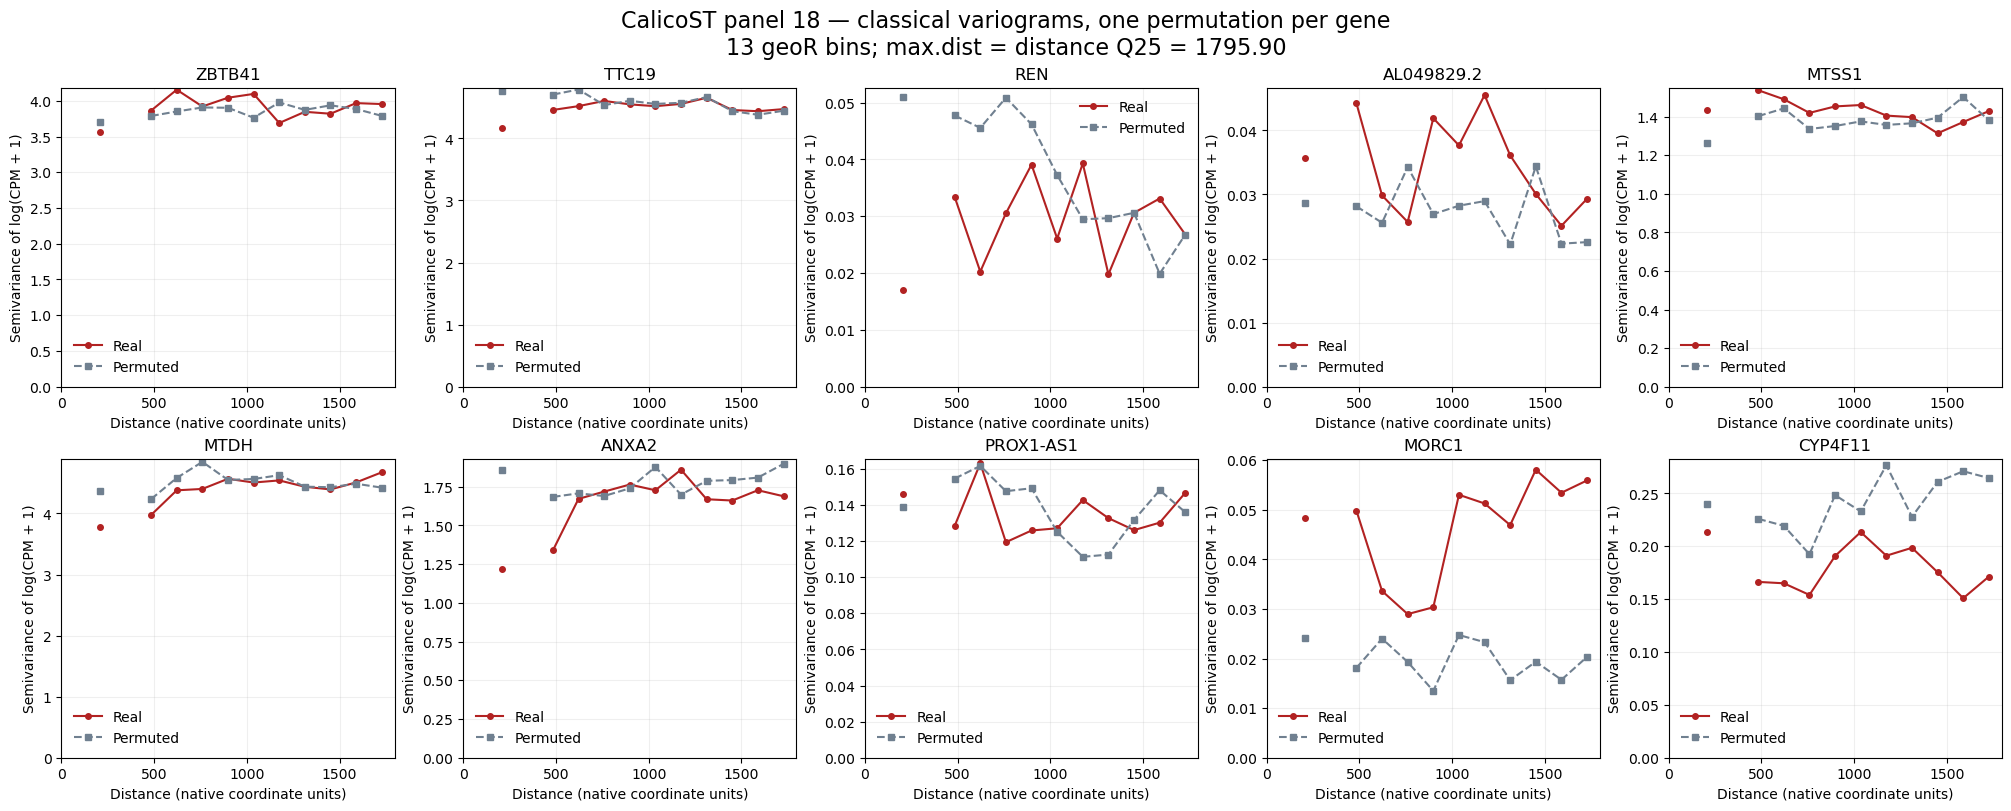

max.dist = 1795.896544; used 20,039 of 80,200 unordered pairs. geoR bin endpoint = 1795.896535.


,lag_center,left_edge,right_edge,n_pairs
0,69.072944,1.000000e-12,138.145887,0
1,207.218831,1.381459e+02,276.291775,859
2,345.364718,2.762918e+02,414.437662,0
3,483.510606,4.144377e+02,552.583549,1528
4,621.656493,5.525835e+02,690.729437,1441
5,759.802380,6.907294e+02,828.875324,717
6,897.948268,8.288753e+02,967.021211,2053
7,1036.094155,9.670212e+02,1105.167099,1958
8,1174.240042,1.105167e+03,1243.312986,1485
9,1312.385929,1.243313e+03,1381.458873,2213


In [2]:
# Exact 25th-percentile cutoff from all unordered pairs, then geoR's 13 bins.
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist

all_distances = pdist(coords, metric="euclidean")
max_dist = float(np.quantile(all_distances, 0.25))
total_pairs = all_distances.size
below_cutoff = all_distances[all_distances < max_dist]
if below_cutoff.size == 0 or all_distances.min() <= 1e-12:
    raise ValueError("Expected distinct, separated coordinates.")
bin_max_dist = float(below_cutoff.max())
del all_distances, below_cutoff
if max_dist <= 0:
    raise ValueError("The 25th-percentile distance must be positive.")

bin_edges = np.linspace(0.0, bin_max_dist, N_BINS + 1)
bin_edges[0] = 1e-12
lag_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

pairs = cKDTree(coords).query_pairs(max_dist, output_type="ndarray")
pair_distances = np.linalg.norm(coords[pairs[:, 0]] - coords[pairs[:, 1]], axis=1)
inside = (pair_distances >= bin_edges[0]) & (pair_distances < bin_edges[-1])
pairs, pair_distances = pairs[inside], pair_distances[inside]
bin_index = np.searchsorted(bin_edges[1:-1], pair_distances, side="right")
pair_counts = np.bincount(bin_index, minlength=N_BINS)
valid_bins = pair_counts >= 2

def classical_variogram(expression):
    # Half the mean squared expression difference in each shared distance bin.
    result = np.full((N_BINS, expression.shape[1]), np.nan)
    for j in range(expression.shape[1]):
        difference = expression[pairs[:, 0], j] - expression[pairs[:, 1], j]
        squared_sum = np.bincount(bin_index, weights=difference**2, minlength=N_BINS)
        result[valid_bins, j] = squared_sum[valid_bins] / (2.0 * pair_counts[valid_bins])
    return result

variogram_real = classical_variogram(log_cpm)
variogram_permuted = classical_variogram(permuted_log_cpm)
assert pair_counts.sum() == len(pairs)
assert np.all(variogram_real[valid_bins] >= 0)
assert np.all(variogram_permuted[valid_bins] >= 0)
assert len(bin_edges) == N_BINS + 1
np.testing.assert_allclose(np.diff(bin_edges), bin_max_dist / N_BINS, atol=2e-12)
np.testing.assert_array_equal(np.histogram(pair_distances, bins=bin_edges)[0], pair_counts)

fig, axes = plt.subplots(2, 5, figsize=(20, 8), constrained_layout=True)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    ax.plot(lag_centers, variogram_real[:, j], "o-", color="firebrick",
            markersize=4, label="Real")
    ax.plot(lag_centers, variogram_permuted[:, j], "s--", color="slategray",
            markersize=4, label="Permuted")
    ax.set(title=gene, xlabel="Distance (native coordinate units)",
           ylabel="Semivariance of log(CPM + 1)", xlim=(0, max_dist), ylim=(0, None))
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle(
    "CalicoST panel 18 — classical variograms, one permutation per gene\n"
    f"13 geoR bins; max.dist = distance Q25 = {max_dist:.2f}",
    fontsize=16,
)
plt.show()
bin_summary = pd.DataFrame({
    "lag_center": lag_centers,
    "left_edge": bin_edges[:-1],
    "right_edge": bin_edges[1:],
    "n_pairs": pair_counts,
})
print(
    f"max.dist = {max_dist:.6f}; used {len(pairs):,} of {total_pairs:,} unordered pairs. "
    f"geoR bin endpoint = {bin_max_dist:.6f}."
)
display(bin_summary)


In [3]:
# Adaptive locfit-style Gaussian weights on the panel coordinates.
from scipy.spatial.distance import cdist

LOCFIT_GAUSSIAN_FACTOR = 2.5
nn_candidates = np.array([0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
if nn_candidates[0] != 0 or np.count_nonzero(nn_candidates == 0) != 1:
    raise ValueError("The bandwidth grid must contain nn=0 exactly once, in the first entry.")
if np.any((nn_candidates < 0) | (nn_candidates > 1)):
    raise ValueError("nn candidates must lie in [0, 1].")

distance2 = cdist(coords, coords, metric="sqeuclidean")
positive = np.flatnonzero(nn_candidates > 0)
neighbor_counts = np.ceil(nn_candidates[positive] * (n_cells - 1)).astype(int)
kth_distance2 = np.partition(distance2, neighbor_counts, axis=1)[:, neighbor_counts]
if np.any(kth_distance2 <= 0):
    raise ValueError("A bandwidth is zero; check for duplicate coordinates.")

adaptive_weights = []
for local_k in range(len(positive)):
    weights = np.exp(
        -0.5 * LOCFIT_GAUSSIAN_FACTOR**2 * distance2 / kth_distance2[:, local_k, None]
    )
    weights /= weights.sum(axis=1, keepdims=True)
    adaptive_weights.append(weights)
np.testing.assert_allclose(adaptive_weights[0].sum(axis=1), 1.0, atol=1e-8)
del distance2

candidate_raw = np.empty((len(nn_candidates), n_cells, n_genes), dtype=float)
candidate_raw[0] = permuted_log_cpm
for local_k, weights in enumerate(adaptive_weights):
    candidate_raw[positive[local_k]] = weights @ permuted_log_cpm
candidate_raw_variograms = np.stack([classical_variogram(field) for field in candidate_raw])
np.testing.assert_allclose(candidate_raw_variograms[0], variogram_permuted, equal_nan=True)
print(
    f"Adaptive Gaussian grid on {n_cells} spots: "
    + ", ".join(f"{nn:g}" for nn in nn_candidates)
)


Adaptive Gaussian grid on 401 spots: 0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9


In [4]:
# Unconstrained STCompare-style match, then final mean/SD normalization.
candidate_matched = candidate_raw.copy()
candidate_variograms = candidate_raw_variograms.copy()
fit_coefficients = np.full((len(nn_candidates), n_genes, 2), np.nan)
fit_coefficients[0, :, :] = (0.0, 1.0)
candidate_sse = np.empty((len(nn_candidates), n_genes))
for j in range(n_genes):
    noise_rng = np.random.default_rng(1)
    for k in range(1, len(nn_candidates)):
        design = np.column_stack((
            np.ones(valid_bins.sum()),
            candidate_raw_variograms[k, valid_bins, j],
        ))
        beta, _, rank, _ = np.linalg.lstsq(design, variogram_real[valid_bins, j], rcond=None)
        if rank < 2:
            raise ValueError(f"Singular variogram fit: {selected_genes[j]}, nn={nn_candidates[k]}")
        fit_coefficients[k, j] = beta
        candidate_matched[k, :, j] = (
            np.sqrt(abs(beta[1])) * candidate_raw[k, :, j]
            + np.sqrt(abs(beta[0])) * noise_rng.standard_normal(n_cells)
        )
for k, field in enumerate(candidate_matched):
    if k > 0:
        candidate_variograms[k] = classical_variogram(field)
    candidate_sse[k] = np.sum(
        (candidate_variograms[k, valid_bins] - variogram_real[valid_bins]) ** 2, axis=0
    )

best_indices = np.argmin(candidate_sse, axis=0)
best_nn = nn_candidates[best_indices]
best_matched_before_normalization = np.column_stack([
    candidate_matched[k, :, j] for j, k in enumerate(best_indices)
])
target_mean = log_cpm.mean(axis=0)
target_std = log_cpm.std(axis=0, ddof=0)
matched_mean = best_matched_before_normalization.mean(axis=0)
matched_std = best_matched_before_normalization.std(axis=0, ddof=0)
if np.any(matched_std <= 0):
    raise ValueError("Cannot normalize a constant matched field.")
final_scale = target_std / matched_std
best_matched = target_mean + (best_matched_before_normalization - matched_mean) * final_scale
identity_genes = best_nn == 0
best_matched[:, identity_genes] = permuted_log_cpm[:, identity_genes]
final_scale[identity_genes] = 1.0
best_variograms = classical_variogram(best_matched)
np.testing.assert_allclose(best_matched.mean(axis=0), target_mean, atol=1e-12)
np.testing.assert_allclose(best_matched.std(axis=0), target_std, atol=1e-12)
np.testing.assert_array_equal(candidate_matched[0], permuted_log_cpm)


In [5]:
# Variance-constrained match on standardized genes. nn=0 stays the permutation.
vc_mean = log_cpm.mean(axis=0)
vc_std = log_cpm.std(axis=0, ddof=0)
if np.any(vc_std <= 0):
    raise ValueError("Variance-constrained matching requires nonconstant genes.")
vc_true = (log_cpm - vc_mean) / vc_std
vc_permuted = (permuted_log_cpm - vc_mean) / vc_std
vc_target_gamma = variogram_real / vc_std**2
vc_permuted_gamma = variogram_permuted / vc_std**2
np.testing.assert_allclose(vc_true.mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_allclose(vc_true.var(axis=0), 1.0, atol=1e-12)
np.testing.assert_allclose(classical_variogram(vc_true), vc_target_gamma, equal_nan=True)
np.testing.assert_allclose(
    classical_variogram((best_matched - target_mean) / vc_std),
    best_variograms / vc_std**2,
    equal_nan=True,
)

vc_noise = np.random.default_rng(SEED + 20).standard_normal(vc_true.shape)
vc_noise -= vc_noise.mean(axis=0)
vc_noise /= vc_noise.std(axis=0, ddof=0)
np.testing.assert_allclose(vc_noise.var(axis=0), 1.0, atol=1e-12)

def variance_constrained_match(raw_fields, raw_variograms, labels, identity_index=None):
    # Fit a + b*gamma_Y subject to a + b*Var(Y) = 1, with a, b >= 0.
    smooth = (raw_fields - vc_mean) / vc_std
    smooth -= smooth.mean(axis=1, keepdims=True)
    variance = smooth.var(axis=1, ddof=0)
    gamma_y = raw_variograms / vc_std**2
    q = gamma_y[:, valid_bins, :] - variance[:, None, :]
    target_offset = vc_target_gamma[valid_bins] - 1.0
    denominator = np.sum(q**2, axis=1)
    numerator = np.sum(q * target_offset[None, :, :], axis=1)
    b = np.divide(
        numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0
    )
    upper = np.divide(1.0, variance, out=np.zeros_like(variance), where=variance > 0)
    b = np.clip(b, 0.0, upper)
    a = np.maximum(1.0 - b * variance, 0.0)
    if identity_index is not None:
        np.testing.assert_allclose(variance[identity_index], 1.0, atol=1e-12)
        a[identity_index] = 0.0
        b[identity_index] = 1.0
    fitted = a[:, None, :] + b[:, None, :] * gamma_y
    model_sse = np.sum((fitted[:, valid_bins] - vc_target_gamma[valid_bins])**2, axis=1)
    mixed = np.sqrt(b[:, None, :]) * smooth + np.sqrt(a[:, None, :]) * vc_noise
    if identity_index is not None:
        mixed[identity_index] = vc_permuted
    realized = np.stack([classical_variogram(field) for field in mixed])
    realized_sse = np.sum((realized[:, valid_bins] - vc_target_gamma[valid_bins])**2, axis=1)
    realized_variance = mixed.var(axis=1, ddof=0)
    cross_covariance = np.mean(smooth * vc_noise[None, :, :], axis=1)
    component_variance = a + b * variance
    np.testing.assert_allclose(component_variance, 1.0, atol=1e-12)
    np.testing.assert_allclose(
        realized_variance,
        component_variance + 2 * np.sqrt(a * b) * cross_covariance,
        atol=1e-12,
    )
    best = model_sse.argmin(axis=0)
    genes = np.arange(vc_true.shape[1])
    best_field = np.column_stack([mixed[k, :, j] for j, k in enumerate(best)])
    best_gamma = np.column_stack([realized[k, :, j] for j, k in enumerate(best)])
    best_variance = realized_variance[best, genes]
    if np.any(best_variance <= 0):
        raise ValueError("A selected variance-constrained surrogate is constant.")
    summary = pd.DataFrame({
        "gene": selected_genes,
        "best_candidate": np.asarray(labels)[best],
        "a_noise": a[best, genes],
        "b_smooth": b[best, genes],
        "smooth_variance": variance[best, genes],
        "realized_variance": best_variance,
        "constrained_fit_SSE": model_sse[best, genes],
        "realized_SSE": realized_sse[best, genes],
    })
    return dict(
        labels=np.asarray(labels), a=a, b=b, smooth=smooth, fitted=fitted,
        realized=realized, model_sse=model_sse, realized_sse=realized_sse,
        best=best, best_field=best_field, best_gamma=best_gamma, summary=summary,
    )

vc_adaptive = variance_constrained_match(
    candidate_raw, candidate_raw_variograms, nn_candidates, identity_index=0,
)


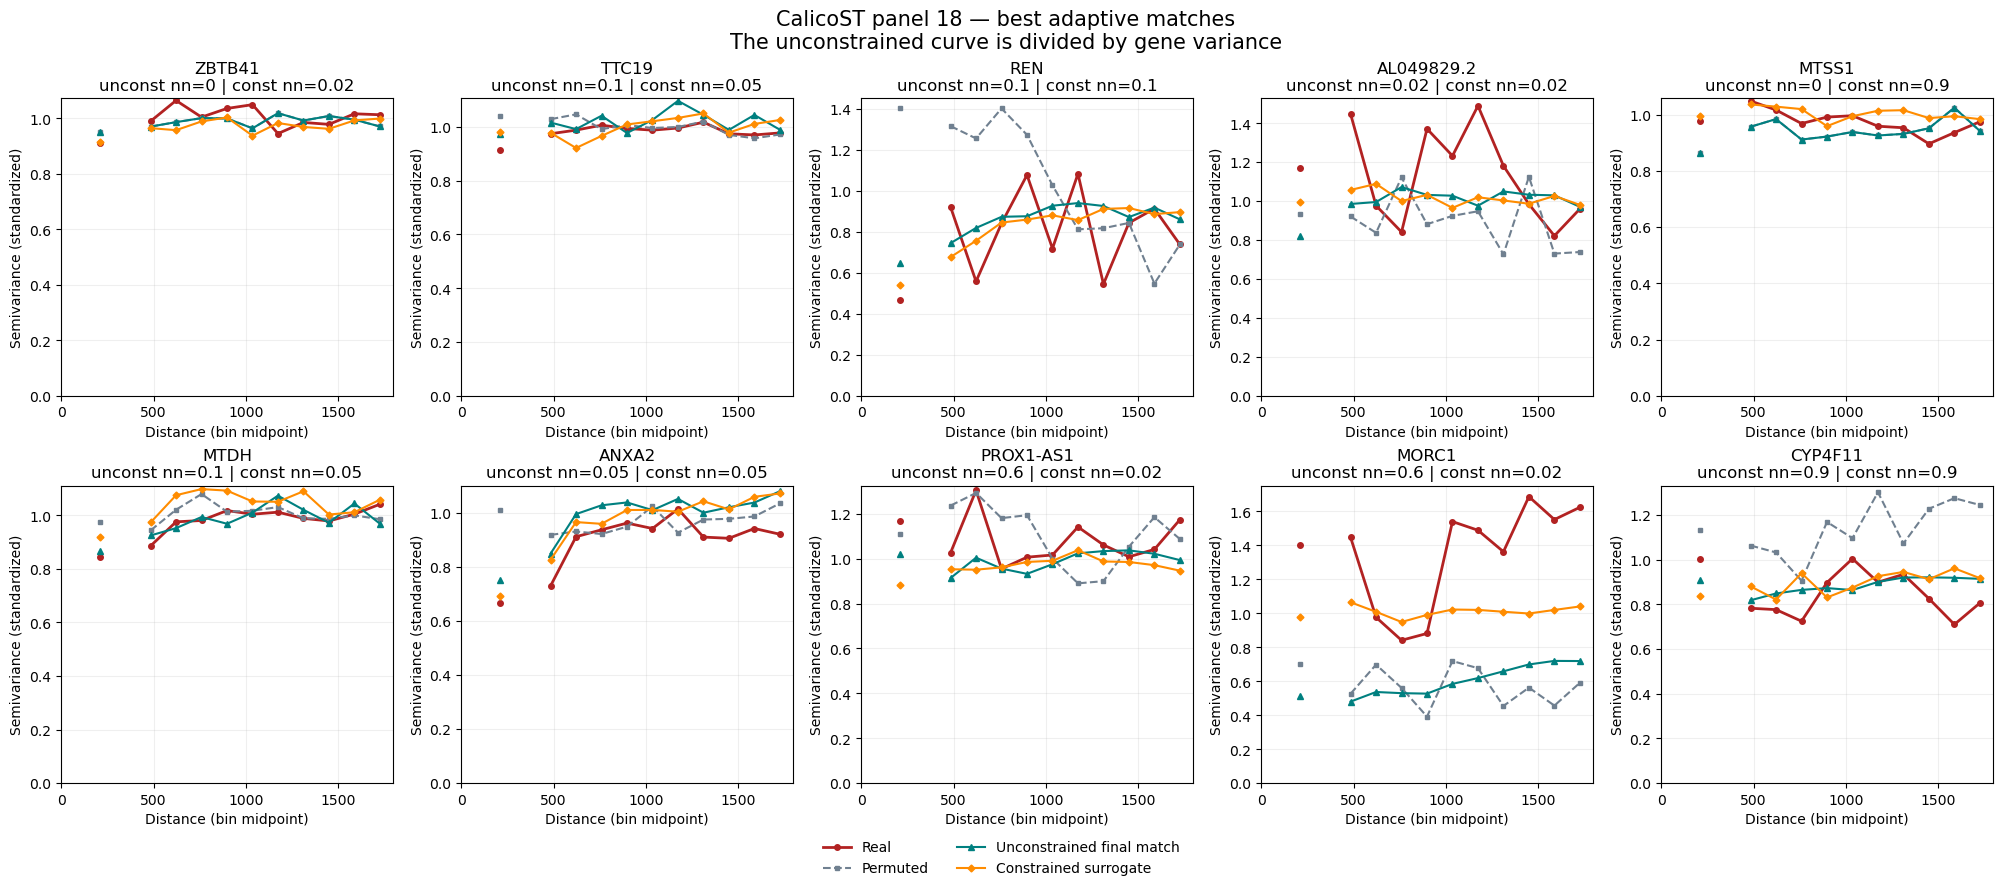

,gene,unconstrained_nn,constrained_nn,unconstrained_standardized_SSE,constrained_theoretical_SSE,constrained_realized_SSE,constrained_a,constrained_b,constrained_realized_variance
0,ZBTB41,0.00,0.02,0.025075,0.015083,0.028611,0.910082,0.441472,0.962862
1,TTC19,0.10,0.05,0.025427,0.003224,0.018443,0.898661,1.964697,0.977724
2,REN,0.10,0.10,0.397590,0.370002,0.393904,0.486427,11.836394,0.987858
3,AL049829.2,0.02,0.02,0.872204,0.751143,0.701021,1.000000,0.000000,1.000000
4,MTSS1,0.00,0.90,0.047303,0.019908,0.023095,0.975653,18.448738,1.006089
5,MTDH,0.10,0.05,0.016974,0.005372,0.057607,0.814978,2.009063,1.045991
6,ANXA2,0.05,0.05,0.104747,0.063660,0.085982,0.596648,6.130915,1.007351
7,PROX1-AS1,0.60,0.02,0.180283,0.178151,0.286903,0.955473,0.249860,0.995397
8,MORC1,0.60,0.02,6.800696,2.230124,2.062582,1.000000,0.000000,1.000000
9,CYP4F11,0.90,0.90,0.120474,0.147103,0.190040,0.815679,109.953396,0.958468


In [6]:
# Real, permuted, unconstrained, and variance-constrained matches on the standardized scale.
unconstrained_gamma = best_variograms / vc_std**2
constrained_gamma = vc_adaptive["best_gamma"]
fig, axes = plt.subplots(2, 5, figsize=(20, 8.8), constrained_layout=True)
for j, (ax, gene) in enumerate(zip(axes.flat, selected_genes)):
    ax.plot(lag_centers, vc_target_gamma[:, j], "o-", color="firebrick",
            markersize=4, linewidth=2, label="Real")
    ax.plot(lag_centers, vc_permuted_gamma[:, j], "s--", color="slategray",
            markersize=3, label="Permuted")
    ax.plot(lag_centers, unconstrained_gamma[:, j], "^-", color="teal",
            markersize=4, label="Unconstrained final match")
    ax.plot(lag_centers, constrained_gamma[:, j], "D-", color="darkorange",
            markersize=3.5, label="Constrained surrogate")
    const_nn = vc_adaptive["labels"][vc_adaptive["best"][j]]
    ax.set(
        title=(
            f"{gene}\n"
            f"unconst nn={best_nn[j]:g} | const nn={const_nn:g}"
        ),
        xlabel="Distance (bin midpoint)",
        ylabel="Semivariance (standardized)",
        xlim=(0, max_dist), ylim=(0, None),
    )
    ax.grid(alpha=0.2)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(
    "CalicoST panel 18 — best adaptive matches\n"
    "The unconstrained curve is divided by gene variance",
    fontsize=15,
)
plt.show()

comparison = pd.DataFrame({
    "gene": selected_genes,
    "unconstrained_nn": best_nn,
    "constrained_nn": vc_adaptive["labels"][vc_adaptive["best"]],
    "unconstrained_standardized_SSE": np.sum(
        (unconstrained_gamma[valid_bins] - vc_target_gamma[valid_bins])**2, axis=0
    ),
    "constrained_theoretical_SSE": vc_adaptive["summary"]["constrained_fit_SSE"].to_numpy(),
    "constrained_realized_SSE": vc_adaptive["summary"]["realized_SSE"].to_numpy(),
    "constrained_a": vc_adaptive["summary"]["a_noise"].to_numpy(),
    "constrained_b": vc_adaptive["summary"]["b_smooth"].to_numpy(),
    "constrained_realized_variance": vc_adaptive["summary"]["realized_variance"].to_numpy(),
})
display(comparison)


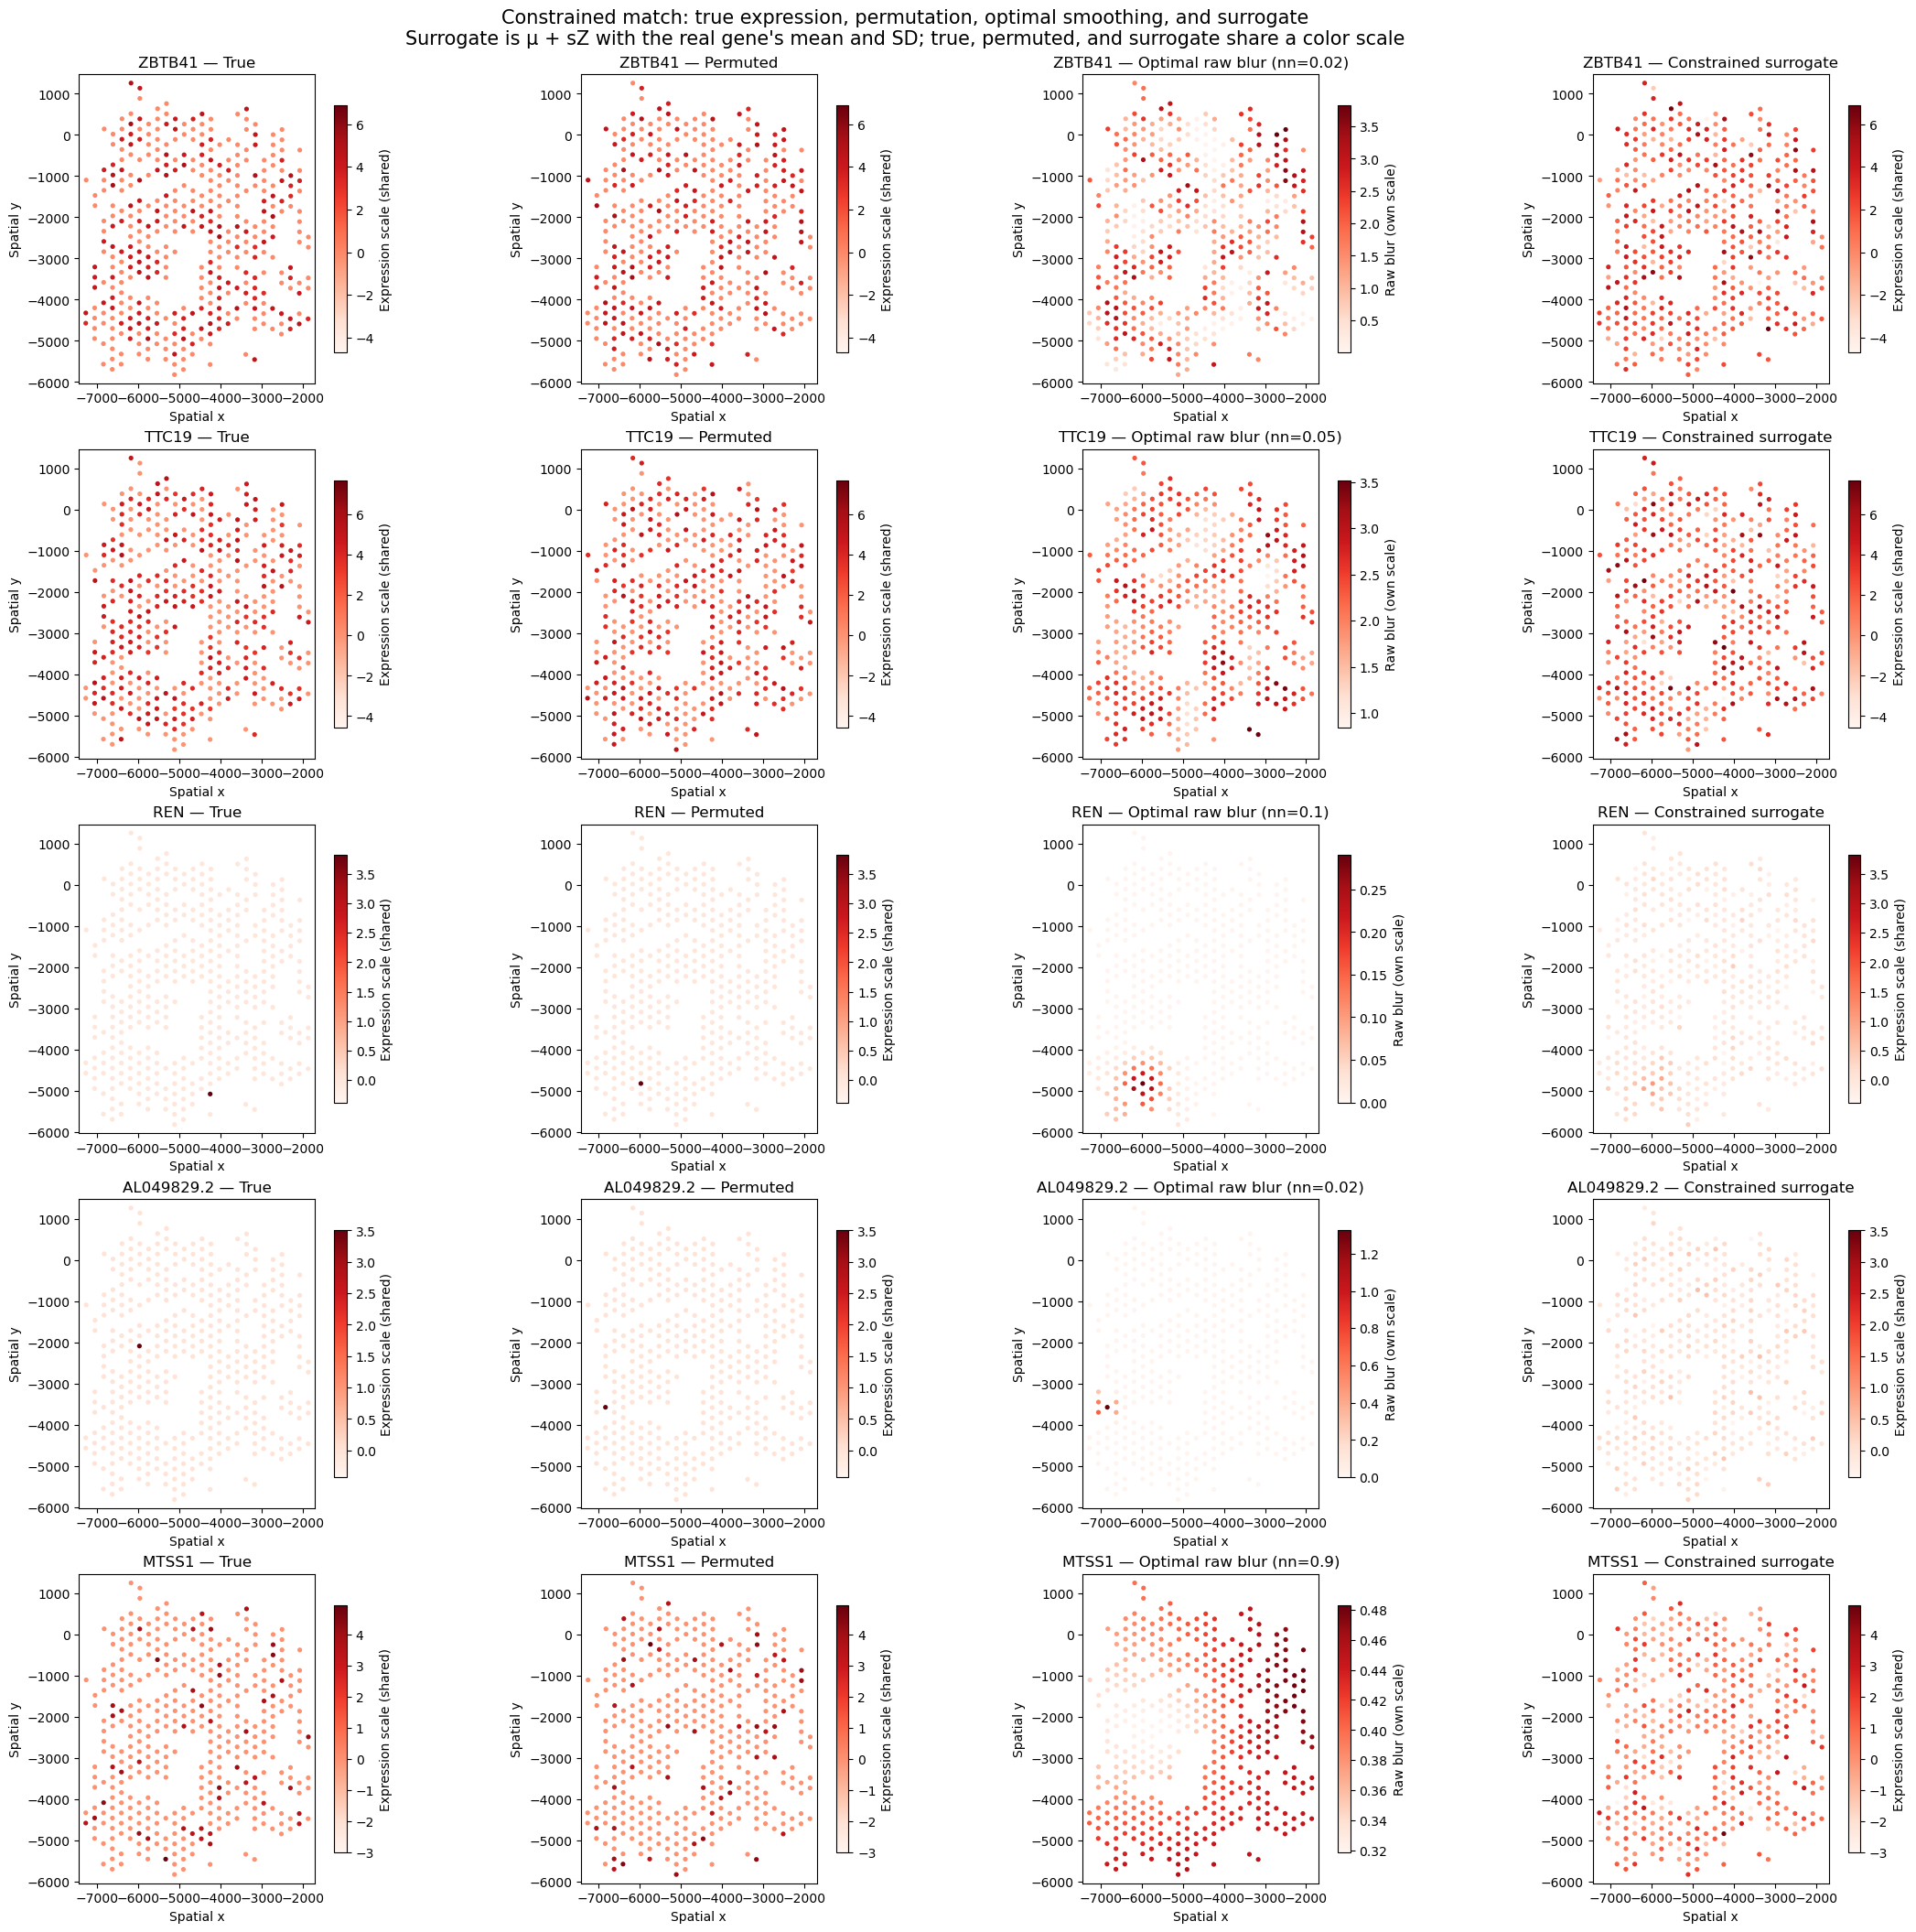

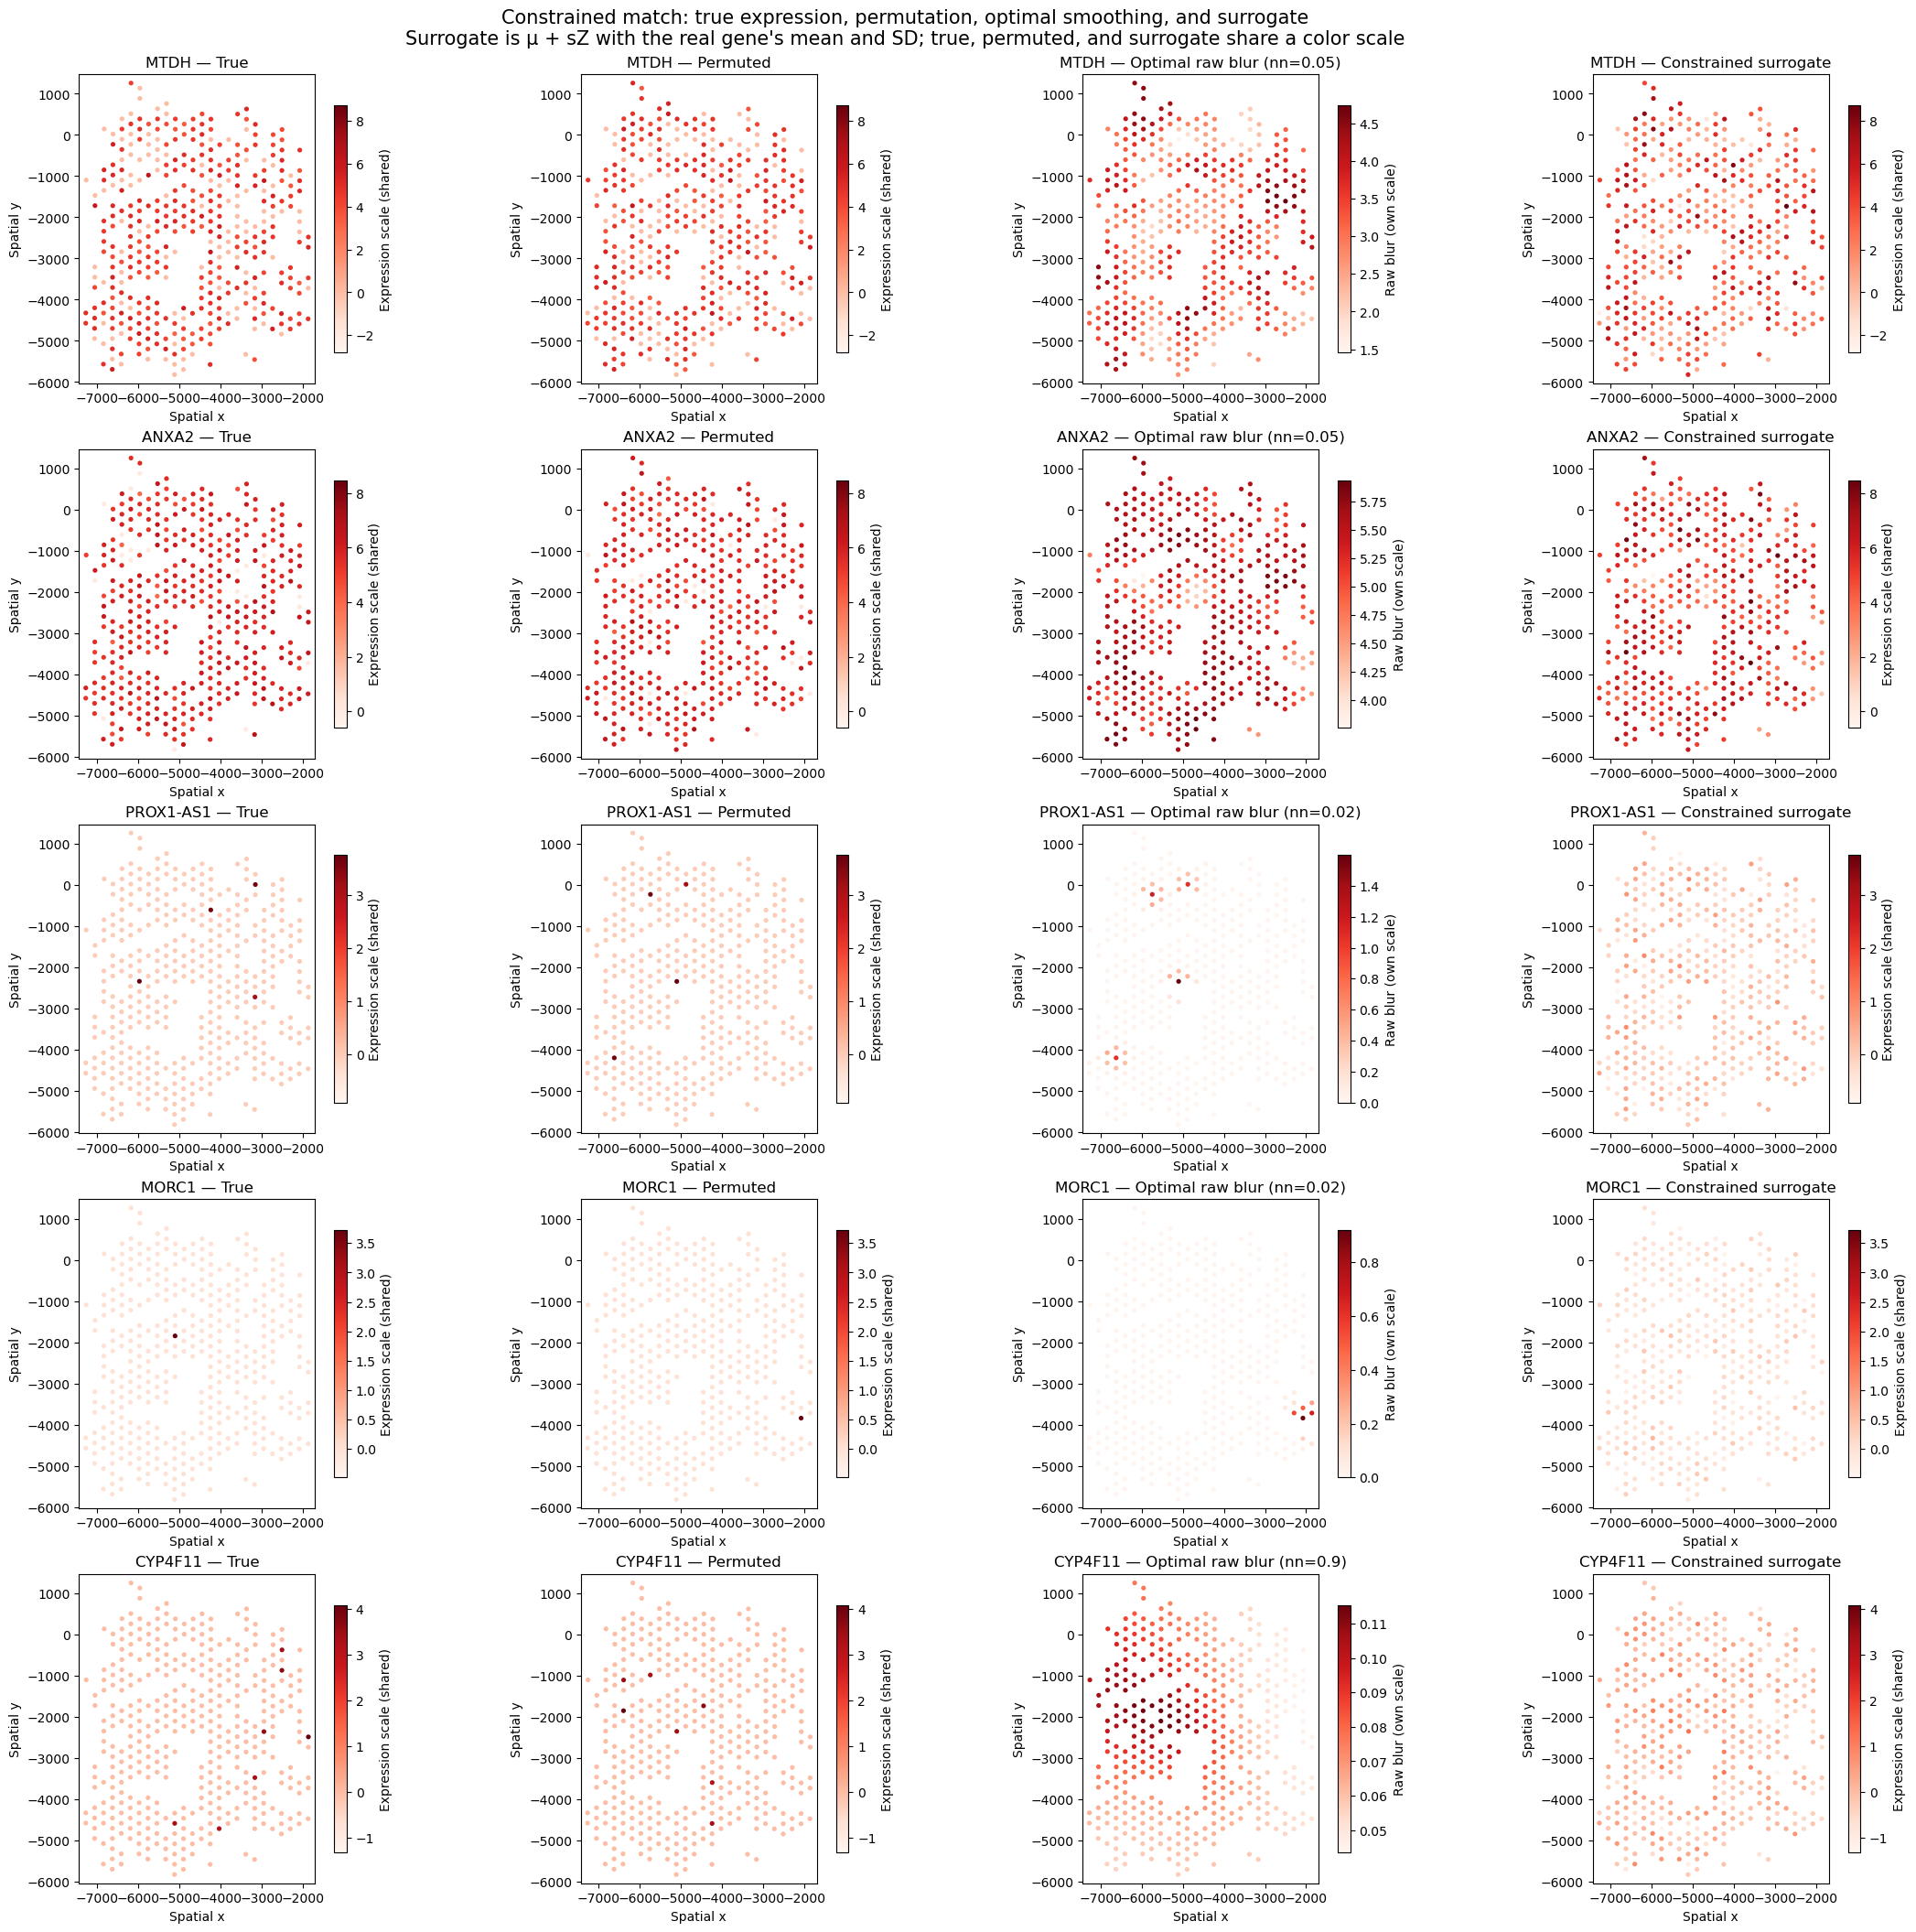

In [7]:
# Four maps for the constrained surrogate: true, permuted, raw blur, and Z.
spatial_min = coords.min(axis=0)
spatial_max = coords.max(axis=0)
spatial_pad = 0.03 * (spatial_max - spatial_min)
constrained_nn = vc_adaptive["labels"][vc_adaptive["best"]]
for start in range(0, n_genes, 5):
    gene_indices = range(start, min(start + 5, n_genes))
    fig, axes = plt.subplots(
        len(gene_indices), 4, figsize=(22, 4.2 * len(gene_indices)),
        constrained_layout=True, squeeze=False,
    )
    for row, j in enumerate(gene_indices):
        k = int(vc_adaptive["best"][j])
        surrogate = vc_mean[j] + vc_std[j] * vc_adaptive["best_field"][:, j]
        fields = (
            log_cpm[:, j],
            permuted_log_cpm[:, j],
            candidate_raw[k, :, j],
            surrogate,
        )
        labels = (
            "True",
            "Permuted",
            f"Optimal raw blur (nn={constrained_nn[j]:g})",
            "Constrained surrogate",
        )
        shared_min = min(float(fields[k_col].min()) for k_col in (0, 1, 3))
        shared_max = max(float(fields[k_col].max()) for k_col in (0, 1, 3))
        for column, (ax, field, label) in enumerate(zip(axes[row], fields, labels)):
            vmin, vmax = (
                (float(field.min()), float(field.max())) if column == 2
                else (shared_min, shared_max)
            )
            if vmax <= vmin:
                vmax = vmin + 1e-12
            points = ax.scatter(
                coords[:, 0], coords[:, 1], c=field, cmap="Reds",
                vmin=vmin, vmax=vmax, s=14, linewidths=0, rasterized=True,
            )
            ax.set(
                title=f"{selected_genes[j]} — {label}",
                xlabel="Spatial x", ylabel="Spatial y",
                xlim=(spatial_min[0] - spatial_pad[0], spatial_max[0] + spatial_pad[0]),
                ylim=(spatial_min[1] - spatial_pad[1], spatial_max[1] + spatial_pad[1]),
            )
            ax.set_aspect("equal", adjustable="box")
            fig.colorbar(
                points, ax=ax, shrink=0.8, pad=0.025,
                label="Raw blur (own scale)" if column == 2 else "Expression scale (shared)",
            )
    fig.suptitle(
        "Constrained match: true expression, permutation, optimal smoothing, and surrogate\n"
        "Surrogate is μ + sZ with the real gene's mean and SD; true, permuted, and surrogate share a color scale",
        fontsize=15,
    )
    plt.show()


## Smoother stability and fit error across panel genes

The ten-gene panel uses one permutation per gene. This section uses every gene with positive log-CPM variance and 100 permutations. Genes are standardized before smoothing. The same adaptive weights and distance bins are reused.

Constrained MSE is the mean squared error of \(a+b\widehat\gamma_Y\) under \(a+b\mathrm{Var}(Y)=1\), \(a,b\geq 0\). Unconstrained MSE is the mean squared error of ordinary least squares \(a+b\widehat\gamma_Y\) with free coefficients. Both score \(nn=0\) as the permutation variogram itself. The reported variance is the population variance of the selected \(nn\) across the 100 permutations, and the reported MSE is the mean of the selected fit's MSE. A gene whose selected bandwidth is identical in every permutation is recorded with variance zero.


In [8]:
import numba

N_STABILITY_PERMUTATIONS = 100
STABILITY_SEED = SEED + 100
STABILITY_BATCH = 500

spots_detected_all = np.asarray((counts > 0).sum(axis=0)).ravel()
all_log_cpm = np.log1p(1e6 * counts / library_size[:, None])
gene_mean = all_log_cpm.mean(axis=0)
gene_std = all_log_cpm.std(axis=0, ddof=0)
usable_genes = np.isfinite(gene_mean) & np.isfinite(gene_std) & (gene_std > 0)
standardized_all = (
    (all_log_cpm[:, usable_genes] - gene_mean[usable_genes]) / gene_std[usable_genes]
)
analyzed_genes = gene_names_all[usable_genes]
analyzed_spots = spots_detected_all[usable_genes]
n_analyzed = standardized_all.shape[1]
np.testing.assert_allclose(standardized_all.mean(axis=0), 0.0, atol=1e-10)
np.testing.assert_allclose(standardized_all.var(axis=0), 1.0, atol=1e-10)
if len(adaptive_weights) + 1 != len(nn_candidates):
    raise ValueError("Adaptive weights do not match the nn grid.")
del all_log_cpm

pair_i = np.ascontiguousarray(pairs[:, 0], dtype=np.int32)
pair_j = np.ascontiguousarray(pairs[:, 1], dtype=np.int32)
bin_index_i32 = np.ascontiguousarray(bin_index, dtype=np.int32)

@numba.njit(parallel=True, fastmath=True)
def _squared_difference_sums(values_T, pair_i, pair_j, bin_index, n_bins):
    # Sum of squared endpoint differences per column. values_T is stored (columns, spots).
    n_cols = values_T.shape[0]
    sums = np.zeros((n_cols, n_bins))
    n_pairs = pair_i.shape[0]
    for c in numba.prange(n_cols):
        row = values_T[c]
        acc = sums[c]
        for p in range(n_pairs):
            d = row[pair_i[p]] - row[pair_j[p]]
            acc[bin_index[p]] += d * d
    return sums

def batch_variogram(values):
    # Classical semivariogram of each column, using the shared panel bins.
    sums = _squared_difference_sums(
        np.ascontiguousarray(np.asarray(values, dtype=np.float64).T),
        pair_i, pair_j, bin_index_i32, N_BINS,
    )
    result = np.full((N_BINS, values.shape[1]), np.nan)
    result[valid_bins] = (sums[:, valid_bins] / (2.0 * pair_counts[valid_bins])).T
    return result

probe = standardized_all[:, : min(3, n_analyzed)]
np.testing.assert_allclose(
    batch_variogram(probe), classical_variogram(probe),
    rtol=1e-10, atol=1e-8, equal_nan=True,
)

def constrained_curve_mse(gamma_y, variance, gamma_real):
    # MSE of a + b*gamma_Y with a + b*Var(Y) = 1 and a, b >= 0.
    q = gamma_y[valid_bins] - variance[None, :, :]
    offset = gamma_real[valid_bins][:, None, :] - 1.0
    denominator = np.sum(q * q, axis=0)
    numerator = np.sum(q * offset, axis=0)
    b = np.divide(
        numerator, denominator, out=np.zeros_like(numerator), where=denominator > 0
    )
    upper = np.divide(1.0, variance, out=np.zeros_like(variance), where=variance > 0)
    b = np.clip(b, 0.0, upper)
    a = np.maximum(1.0 - b * variance, 0.0)
    np.testing.assert_allclose(a + b * variance, 1.0, atol=1e-8)
    fitted = a[None, :, :] + b[None, :, :] * gamma_y
    error = fitted[valid_bins] - gamma_real[valid_bins][:, None, :]
    return np.mean(error * error, axis=0)

def unconstrained_curve_mse(gamma_y, gamma_real):
    # MSE of ordinary least squares a + b*gamma_Y with free a and b.
    x = gamma_y[valid_bins]
    y = gamma_real[valid_bins][:, None, :]
    x_mean = x.mean(axis=0)
    y_mean = y.mean(axis=0)
    xc = x - x_mean
    yc = y - y_mean
    varx = np.sum(xc * xc, axis=0)
    slope = np.divide(
        np.sum(xc * yc, axis=0), varx, out=np.zeros_like(varx), where=varx > 0
    )
    intercept = y_mean - slope * x_mean
    fitted = intercept[None] + slope[None] * x
    error = fitted - y
    return np.mean(error * error, axis=0)

gamma_real_all = batch_variogram(standardized_all)
gene_seeds = np.random.SeedSequence(STABILITY_SEED).spawn(n_analyzed)
selected_nn_constrained = np.empty((N_STABILITY_PERMUTATIONS, n_analyzed))
selected_nn_unconstrained = np.empty((N_STABILITY_PERMUTATIONS, n_analyzed))
selected_mse_constrained = np.empty((N_STABILITY_PERMUTATIONS, n_analyzed))
selected_mse_unconstrained = np.empty((N_STABILITY_PERMUTATIONS, n_analyzed))

for start in range(0, n_analyzed, STABILITY_BATCH):
    stop = min(start + STABILITY_BATCH, n_analyzed)
    block = standardized_all[:, start:stop]
    n_block = block.shape[1]
    permuted = np.empty((n_cells, N_STABILITY_PERMUTATIONS, n_block))
    for j, seed in enumerate(gene_seeds[start:stop]):
        rng = np.random.default_rng(seed)
        for p in range(N_STABILITY_PERMUTATIONS):
            permuted[:, p, j] = rng.permutation(block[:, j])
    flat = permuted.reshape(n_cells, N_STABILITY_PERMUTATIONS * n_block)
    gamma_real = gamma_real_all[:, start:stop]
    candidate_mse_c = np.empty((len(nn_candidates), N_STABILITY_PERMUTATIONS, n_block))
    candidate_mse_u = np.empty((len(nn_candidates), N_STABILITY_PERMUTATIONS, n_block))
    gamma_identity = batch_variogram(flat).reshape(
        N_BINS, N_STABILITY_PERMUTATIONS, n_block
    )
    identity_error = gamma_identity[valid_bins] - gamma_real[valid_bins][:, None, :]
    identity_mse = np.mean(identity_error * identity_error, axis=0)
    candidate_mse_c[0] = identity_mse
    candidate_mse_u[0] = identity_mse
    for local_k, weights in enumerate(adaptive_weights):
        smoothed = weights @ flat
        variance = smoothed.var(axis=0, ddof=0).reshape(N_STABILITY_PERMUTATIONS, n_block)
        gamma_y = batch_variogram(smoothed).reshape(
            N_BINS, N_STABILITY_PERMUTATIONS, n_block
        )
        candidate_mse_c[local_k + 1] = constrained_curve_mse(gamma_y, variance, gamma_real)
        candidate_mse_u[local_k + 1] = unconstrained_curve_mse(gamma_y, gamma_real)
        if np.any(candidate_mse_u[local_k + 1] > candidate_mse_c[local_k + 1] + 1e-8):
            raise ValueError("Unconstrained least squares exceeded the constrained curve error.")
        del smoothed
    best_c = np.argmin(candidate_mse_c, axis=0)
    best_u = np.argmin(candidate_mse_u, axis=0)
    selected_nn_constrained[:, start:stop] = nn_candidates[best_c]
    selected_nn_unconstrained[:, start:stop] = nn_candidates[best_u]
    selected_mse_constrained[:, start:stop] = np.take_along_axis(
        candidate_mse_c, best_c[None, ...], axis=0
    )[0]
    selected_mse_unconstrained[:, start:stop] = np.take_along_axis(
        candidate_mse_u, best_u[None, ...], axis=0
    )[0]
    del permuted, flat, gamma_identity
    print(f"Finished genes {start}:{stop} of {n_analyzed}")

def stability_table(selected_nn, selected_mse):
    constant_choice = np.all(selected_nn == selected_nn[0], axis=0)
    choice_variance = selected_nn.var(axis=0, ddof=0)
    choice_variance[constant_choice] = 0.0
    average_mse = selected_mse.mean(axis=0)
    if not np.isfinite(choice_variance).all() or not np.isfinite(average_mse).all():
        raise ValueError("Non-finite smoother-choice variance or fit MSE.")
    return pd.DataFrame({
        "gene": analyzed_genes,
        "spots_detected": analyzed_spots,
        "smoother_choice_variance": choice_variance,
        "average_fit_mse": average_mse,
        "median_selected_nn": np.median(selected_nn, axis=0),
    })

stability_constrained = stability_table(selected_nn_constrained, selected_mse_constrained)
stability_unconstrained = stability_table(selected_nn_unconstrained, selected_mse_unconstrained)
print(
    f"Standardized {n_analyzed}/{len(gene_names_all)} genes "
    f"(dropped {int((~usable_genes).sum())} constant or non-finite). "
    f"{N_STABILITY_PERMUTATIONS} permutations. "
    f"MSE is the mean over {int(valid_bins.sum())} valid distance bins."
)
print(
    "Constrained: median nn-variance "
    f"{stability_constrained['smoother_choice_variance'].median():.4g}, "
    "median average MSE "
    f"{stability_constrained['average_fit_mse'].median():.4g}."
)
print(
    "Unconstrained: median nn-variance "
    f"{stability_unconstrained['smoother_choice_variance'].median():.4g}, "
    "median average MSE "
    f"{stability_unconstrained['average_fit_mse'].median():.4g}."
)
display(stability_constrained.describe())
display(stability_unconstrained.describe())


Finished genes 0:500 of 20708
Finished genes 500:1000 of 20708
Finished genes 1000:1500 of 20708
Finished genes 1500:2000 of 20708
Finished genes 2000:2500 of 20708
Finished genes 2500:3000 of 20708
Finished genes 3000:3500 of 20708
Finished genes 3500:4000 of 20708
Finished genes 4000:4500 of 20708
Finished genes 4500:5000 of 20708
Finished genes 5000:5500 of 20708
Finished genes 5500:6000 of 20708
Finished genes 6000:6500 of 20708
Finished genes 6500:7000 of 20708
Finished genes 7000:7500 of 20708
Finished genes 7500:8000 of 20708
Finished genes 8000:8500 of 20708
Finished genes 8500:9000 of 20708
Finished genes 9000:9500 of 20708
Finished genes 9500:10000 of 20708
Finished genes 10000:10500 of 20708
Finished genes 10500:11000 of 20708
Finished genes 11000:11500 of 20708
Finished genes 11500:12000 of 20708
Finished genes 12000:12500 of 20708
Finished genes 12500:13000 of 20708
Finished genes 13000:13500 of 20708
Finished genes 13500:14000 of 20708
Finished genes 14000:14500 of 20708


,spots_detected,smoother_choice_variance,average_fit_mse,median_selected_nn
count,20708.000000,20708.000000,20708.000000,20708.000000
mean,103.659745,0.019690,0.012719,0.243136
std,112.255499,0.038144,0.027745,0.349104
min,1.000000,0.000000,0.000058,0.000000
25%,7.000000,0.000059,0.000723,0.020000
50%,60.000000,0.000597,0.001705,0.020000
75%,173.000000,0.022035,0.009575,0.300000
max,401.000000,0.196112,0.360732,0.900000


,spots_detected,smoother_choice_variance,average_fit_mse,median_selected_nn
count,20708.000000,20708.000000,20708.000000,20708.000000
mean,103.659745,0.022697,0.005571,0.222399
std,112.255499,0.041172,0.011617,0.307298
min,1.000000,0.000000,0.000038,0.020000
25%,7.000000,0.000205,0.000498,0.020000
50%,60.000000,0.001295,0.000947,0.050000
75%,173.000000,0.026231,0.004156,0.200000
max,401.000000,0.191019,0.118634,0.900000


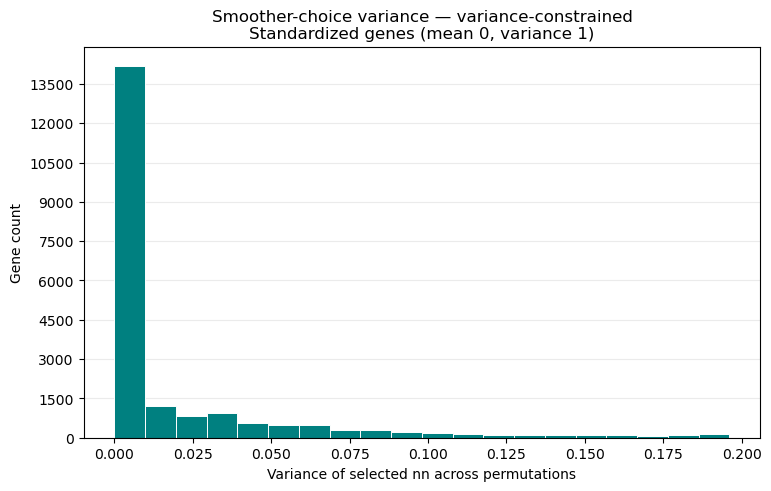

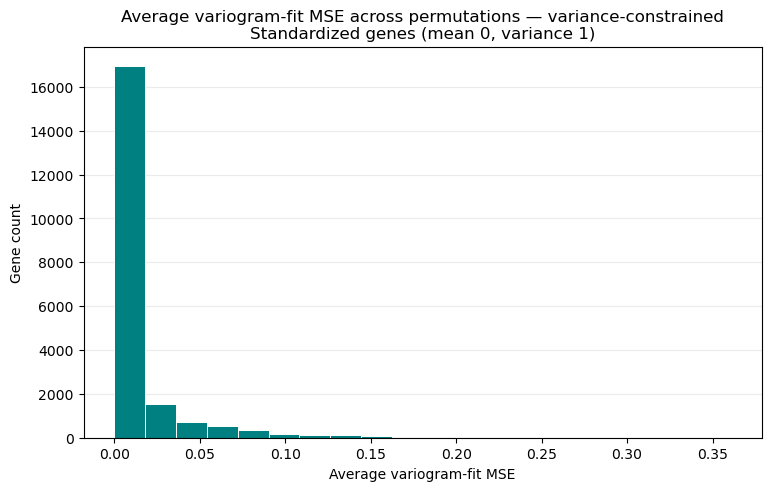

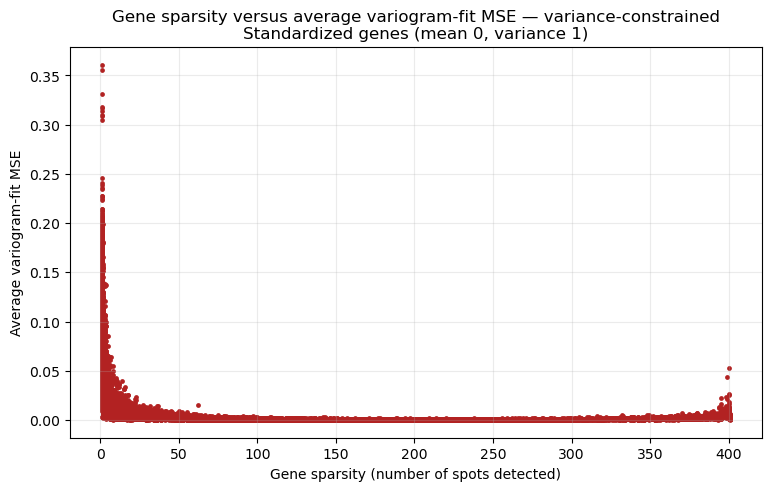

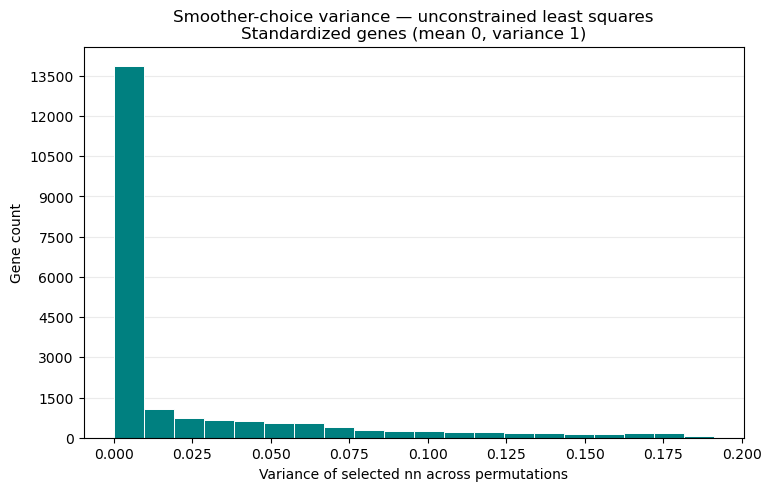

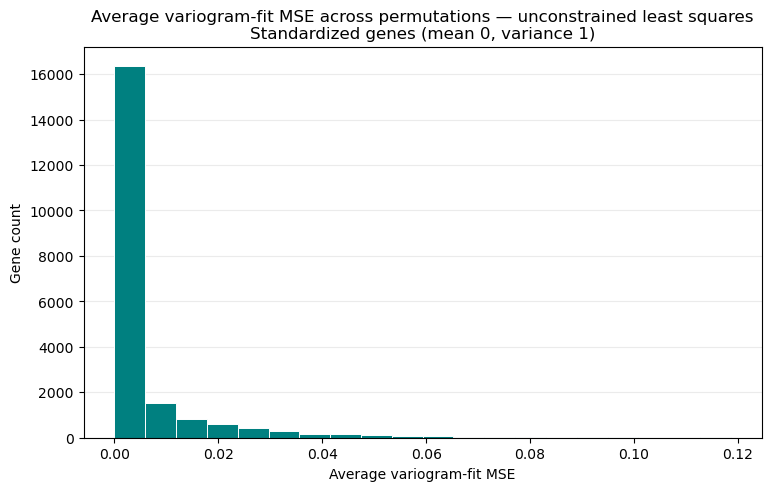

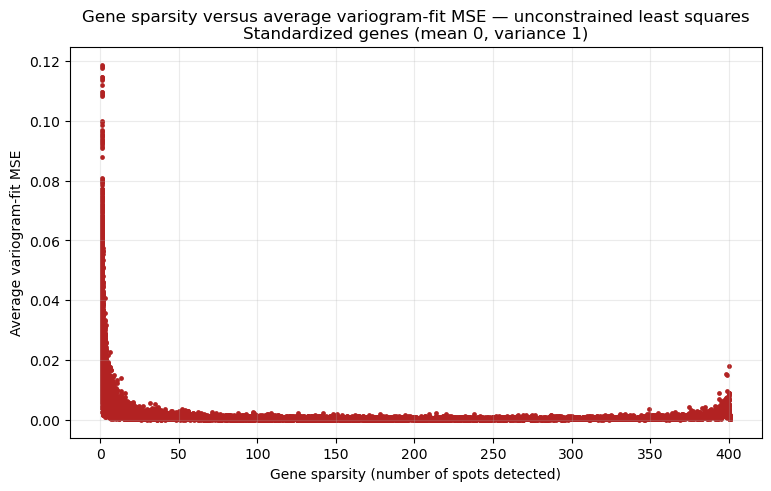

In [9]:
from matplotlib.ticker import MaxNLocator

N_HISTOGRAM_BUCKETS = 20

def nonnegative_bucket_edges(values, n_buckets):
    upper = float(np.max(values))
    if not np.isfinite(upper) or upper <= 0.0:
        upper = 1.0
    return np.linspace(0.0, upper, n_buckets + 1)

def plot_stability_summaries(table, version):
    variance_values = table["smoother_choice_variance"].to_numpy()
    mse_values = table["average_fit_mse"].to_numpy()
    sparsity_values = table["spots_detected"].to_numpy()

    fig, ax = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)
    ax.hist(
        variance_values,
        bins=nonnegative_bucket_edges(variance_values, N_HISTOGRAM_BUCKETS),
        color="teal", edgecolor="white", linewidth=0.7,
    )
    ax.set(
        xlabel="Variance of selected nn across permutations",
        ylabel="Gene count",
        title=f"Smoother-choice variance — {version}\n"
              "Standardized genes (mean 0, variance 1)",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    plt.show()

    fig, ax = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)
    ax.hist(
        mse_values,
        bins=nonnegative_bucket_edges(mse_values, N_HISTOGRAM_BUCKETS),
        color="teal", edgecolor="white", linewidth=0.7,
    )
    ax.set(
        xlabel="Average variogram-fit MSE",
        ylabel="Gene count",
        title=f"Average variogram-fit MSE across permutations — {version}\n"
              "Standardized genes (mean 0, variance 1)",
    )
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    plt.show()

    fig, ax = plt.subplots(figsize=(7.6, 4.8), constrained_layout=True)
    ax.scatter(sparsity_values, mse_values, s=12, c="firebrick", linewidths=0, rasterized=True)
    ax.set(
        xlabel="Gene sparsity (number of spots detected)",
        ylabel="Average variogram-fit MSE",
        title=f"Gene sparsity versus average variogram-fit MSE — {version}\n"
              "Standardized genes (mean 0, variance 1)",
    )
    ax.grid(alpha=0.25)
    plt.show()

plot_stability_summaries(stability_constrained, "variance-constrained")
plot_stability_summaries(stability_unconstrained, "unconstrained least squares")


In [10]:
# Edit these cutoffs and rerun this cell. A gene is kept only if it meets all three.
# Detection percent is the share of panel spots with a positive raw count.
min_detection_percent = 10.0
max_smoother_choice_variance = 0.01
max_average_fit_mse = 0.001

detection_percent = 100.0 * stability_constrained["spots_detected"].to_numpy() / n_cells

def genes_remaining(table, label):
    keep = (
        (detection_percent >= min_detection_percent)
        & (table["smoother_choice_variance"].to_numpy() <= max_smoother_choice_variance)
        & (table["average_fit_mse"].to_numpy() <= max_average_fit_mse)
    )
    print(f"{label}: {int(keep.sum())} of {len(table)} genes")

genes_remaining(stability_constrained, "Variance-constrained")
genes_remaining(stability_unconstrained, "Unconstrained least squares")


Variance-constrained: 5243 of 20708 genes
Unconstrained least squares: 7638 of 20708 genes


Panel 18 clone 1 isodepth: 401 spots, range [0.186, 0.22]. OLS fits use 20708 panel genes. Median fit MSE 0.9851.


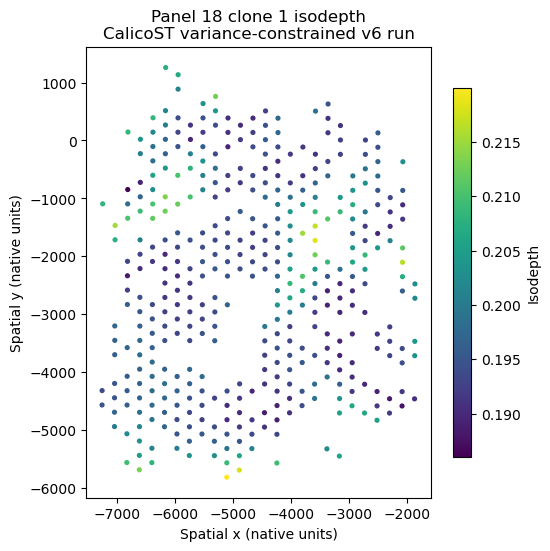

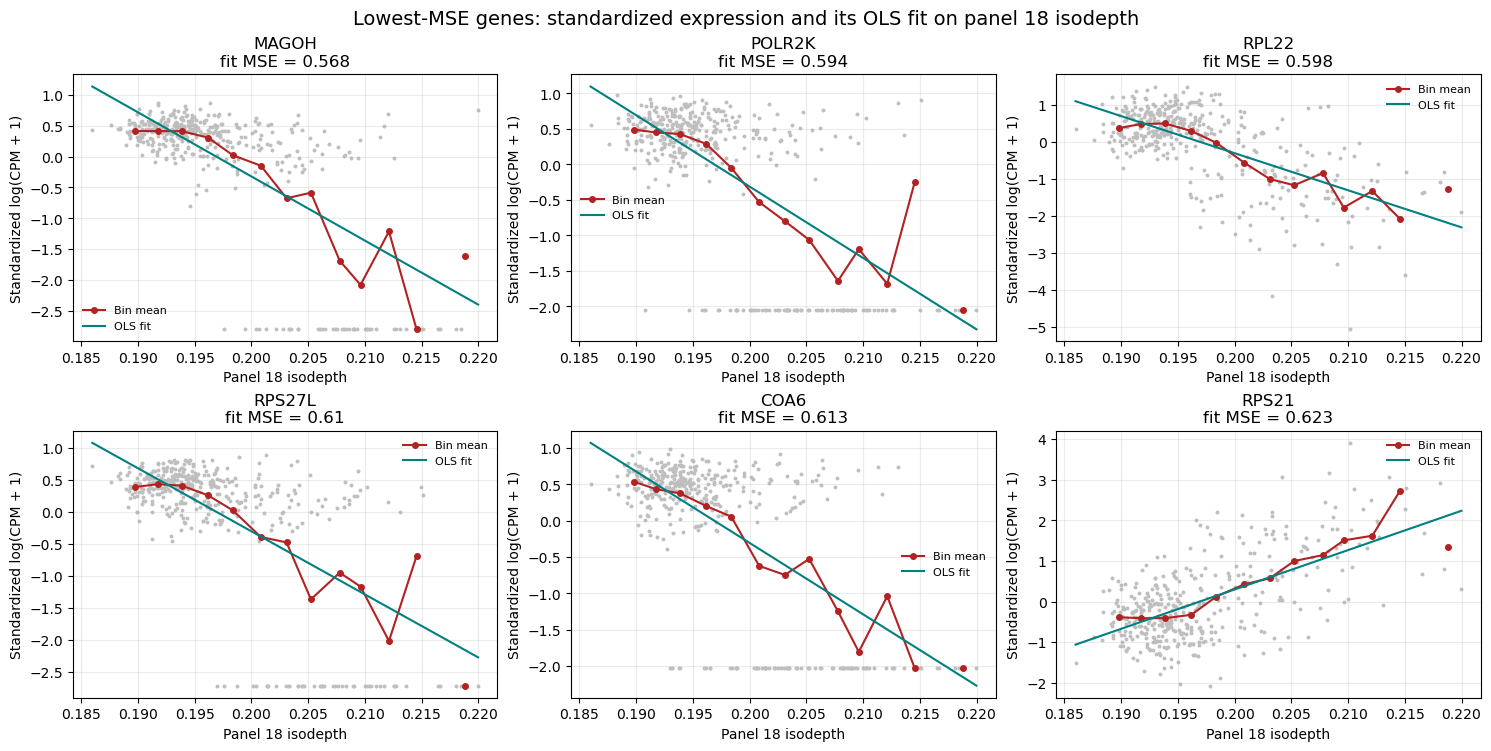

variance-constrained: 20708 genes.


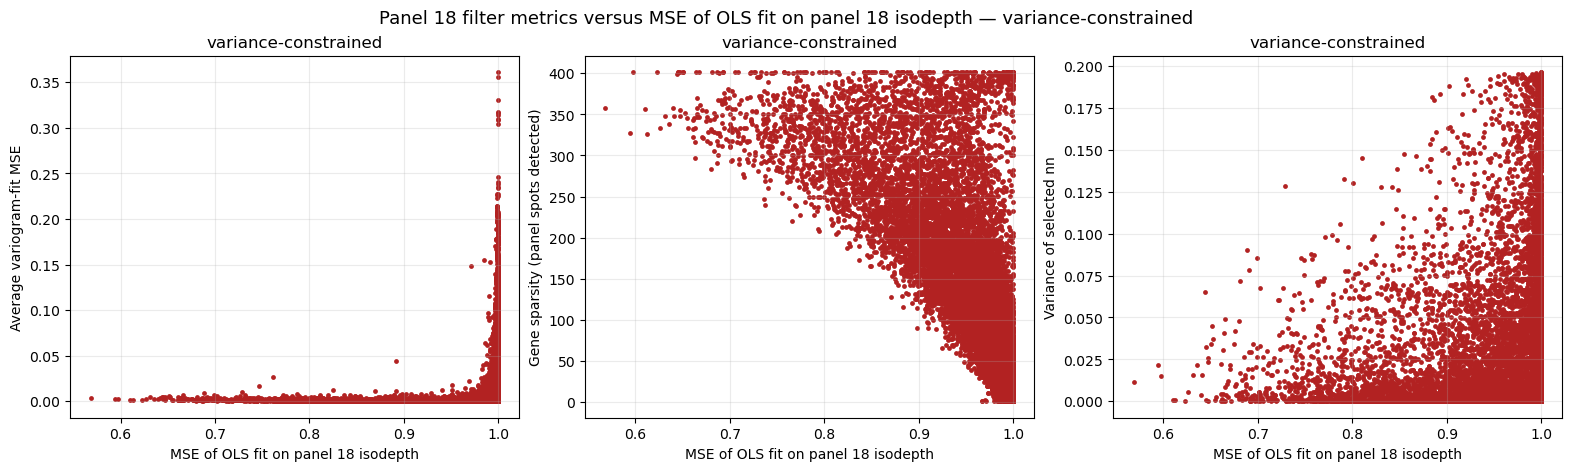

unconstrained least squares: 20708 genes.


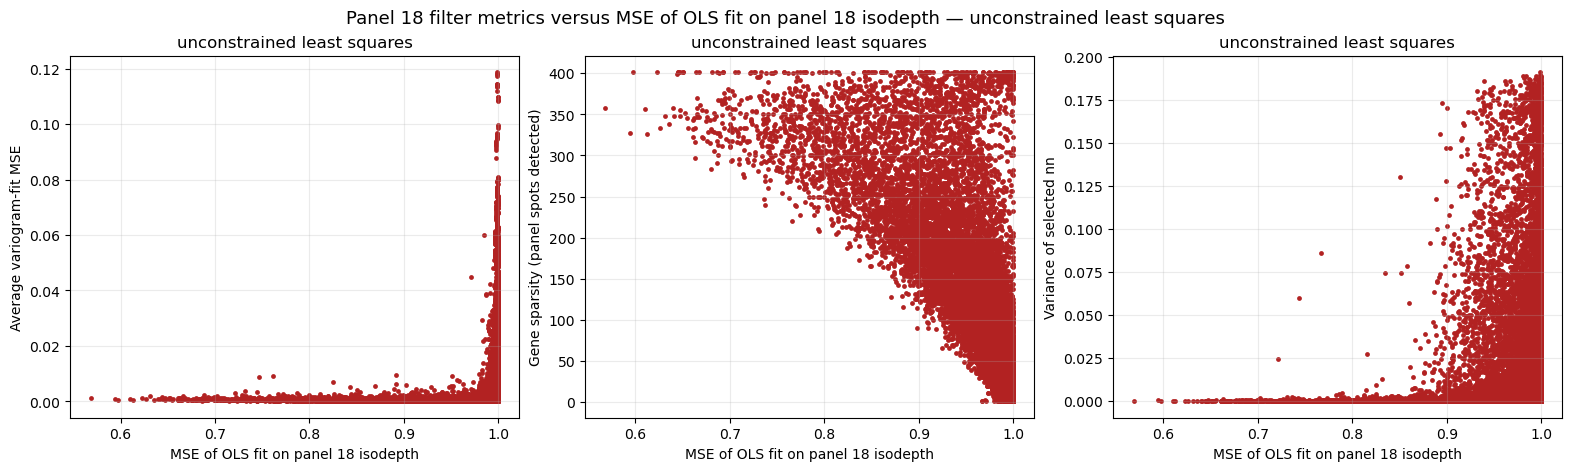

,gene,ols_slope,fit_mse,effect_size,spots_detected,average_fit_mse,smoother_choice_variance
765,MAGOH,-103.693376,0.568312,103.693376,358,0.003288,0.011715
8981,POLR2K,-100.589575,0.593768,100.589575,327,0.002323,0.021914
103,RPL22,-100.105775,0.597667,100.105775,401,0.002785,0.015089
14456,RPS27L,-98.584749,0.609800,98.584749,356,0.001810,0.000471
2092,COA6,-98.223104,0.612658,98.223104,326,0.001680,0.000810
19204,RPS21,96.955541,0.622590,96.955541,401,0.001921,0.000133


In [11]:
# Panel 18 clone 1 isodepth from the variance-constrained v6 run, on the same
# spots used above. Each gene is fit by its own OLS line on that isodepth.
# Fit MSE is the mean squared residual of standardized log-CPM around that line.
# Effect size, used in the next cell, is the absolute OLS slope.
PANEL_ISODEPTH_NPZ = (
    root
    / "results/calicost/cohort_survey/gt1clone/inclusion_gt0p7_qc60"
    / "correlated_null_adaptive_variance_constrained"
    / "panel18_HT268B1_Th1K3Fc2U1Z1Bs1_clone1_cluster0_v6"
    / "1.0"
    / "1.0_isodepths.npz"
)
N_TOP_EFFECT_GENES = 6
N_ISODEPTH_BINS = 15

panel_payload = np.load(PANEL_ISODEPTH_NPZ)
panel_isodepth = np.asarray(panel_payload["true_isodepth"], dtype=np.float64).reshape(-1)
panel_coordinates_saved = np.asarray(panel_payload["S"], dtype=np.float64)
if panel_isodepth.shape[0] != n_cells or panel_coordinates_saved.shape[0] != n_cells:
    raise ValueError(
        f"Saved panel isodepth has {panel_isodepth.shape[0]} spots; this notebook has {n_cells}."
    )
coordinate_sd = coords.std(axis=0, ddof=0)
if np.any(coordinate_sd <= 0):
    raise ValueError("Panel coordinates have no variation.")
coordinate_z = (coords - coords.mean(axis=0)) / coordinate_sd
if not np.allclose(coordinate_z, panel_coordinates_saved, atol=1e-4, rtol=1e-4):
    raise ValueError(
        "Saved panel isodepth is not aligned with this notebook's spots."
    )
if standardized_all.shape != (n_cells, len(analyzed_genes)):
    raise ValueError("Standardized expression does not match the analyzed panel genes.")

import sys
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from data.h5ad_loader import preprocess_celltype_subset

def genes_in_saved_isodepth(raw_counts, all_names, saved_expression, **filter_kwargs):
    # Same count filter, HVG cutoff, library-size normalization, and z-scoring as the run.
    raw_counts = np.asarray(raw_counts, dtype=np.float32)
    saved_expression = np.asarray(saved_expression, dtype=np.float32)
    names = [str(gene) for gene in all_names]
    top_var_genes = int(filter_kwargs.get("top_var_genes", 0))
    pools = [top_var_genes] if top_var_genes else []
    pools.append(0)
    for n_top in pools:
        matrix, matrix_names, _ = preprocess_celltype_subset(
            raw_counts, names, top_var_genes=n_top, **{
                key: value for key, value in filter_kwargs.items() if key != "top_var_genes"
            },
        )
        matrix = np.asarray(matrix, dtype=np.float32)
        if matrix.shape == saved_expression.shape and np.allclose(
            matrix, saved_expression, atol=1e-4, rtol=1e-4
        ):
            return np.asarray(matrix_names)
        correlation = (
            matrix.astype(np.float64).T @ saved_expression.astype(np.float64)
        ) / saved_expression.shape[0]
        best = correlation.argmax(axis=0)
        best_correlation = correlation[best, np.arange(saved_expression.shape[1])]
        if (
            len(set(best.tolist())) == saved_expression.shape[1]
            and float(best_correlation.min()) >= 0.95
        ):
            return np.asarray(matrix_names)[best]
    raise ValueError("Saved isodepth genes do not match this config's gene filter.")

isodepth_genes = genes_in_saved_isodepth(
    counts, gene_names_all, panel_payload["A"],
    min_cells_per_gene=10,
    min_sparsity_percentage=5,
    top_var_genes=3000,
    normalize_total=True,
    log1p=True,
    standardize_expression=True,
    seed=42,
)
fit_mask = np.isin(analyzed_genes, isodepth_genes)
fit_genes = analyzed_genes[fit_mask]
fit_expression = standardized_all[:, fit_mask]
if len(fit_genes) != len(set(map(str, isodepth_genes))):
    missing = len(set(map(str, isodepth_genes)) - set(map(str, analyzed_genes)))
    raise ValueError(f"{missing} isodepth genes are absent from the panel stability table.")
print(
    f"Isodepth gene filter: {len(fit_genes)} genes "
    f"(min 10 cells, 5% sparsity, up to 3000 HVGs; "
    f"{panel_payload['A'].shape[1]} columns in the saved fit)."
)

centered_isodepth = panel_isodepth - float(panel_isodepth.mean())
isodepth_sum_of_squares = float(np.dot(centered_isodepth, centered_isodepth))
if isodepth_sum_of_squares <= 0.0:
    raise ValueError("Panel isodepth has no variation.")
ols_slope = (centered_isodepth @ fit_expression) / isodepth_sum_of_squares
fitted_expression = ols_slope * centered_isodepth[:, None]
fit_mse = np.mean((fit_expression - fitted_expression) ** 2, axis=0)
effect_size = np.abs(ols_slope)
if not np.isfinite(fit_mse).all() or not np.isfinite(effect_size).all():
    raise ValueError("Non-finite panel isodepth fit.")
effect_table = pd.DataFrame({
    "gene": fit_genes,
    "ols_slope": ols_slope,
    "fit_mse": fit_mse,
    "effect_size": effect_size,
})
print(
    f"Panel 18 clone 1 isodepth: {n_cells} spots, "
    f"range [{panel_isodepth.min():.4g}, {panel_isodepth.max():.4g}]. "
    f"OLS fits use {len(fit_genes)} panel genes. "
    f"Median fit MSE {np.median(fit_mse):.4g}."
)

fig, ax = plt.subplots(figsize=(5.6, 5.4), constrained_layout=True)
isodepth_points = ax.scatter(
    coords[:, 0], coords[:, 1], c=panel_isodepth,
    cmap="viridis", s=14, linewidths=0, rasterized=True,
)
ax.set_aspect("equal")
ax.set(
    title="Panel 18 clone 1 isodepth\nCalicoST variance-constrained v6 run",
    xlabel="Spatial x (native units)",
    ylabel="Spatial y (native units)",
)
fig.colorbar(isodepth_points, ax=ax, shrink=0.82, label="Isodepth")
plt.show()

rank = np.argsort(fit_mse)
top_genes = rank[:N_TOP_EFFECT_GENES]
bin_edges = np.linspace(panel_isodepth.min(), panel_isodepth.max(), N_ISODEPTH_BINS + 1)
bin_id = np.clip(
    np.digitize(panel_isodepth, bin_edges[1:-1], right=False),
    0, N_ISODEPTH_BINS - 1,
)
fig, axes = plt.subplots(2, 3, figsize=(14.8, 7.4), constrained_layout=True)
for ax, gene_index in zip(axes.flat, top_genes):
    expression = fit_expression[:, gene_index]
    bin_center = np.full(N_ISODEPTH_BINS, np.nan)
    bin_mean = np.full(N_ISODEPTH_BINS, np.nan)
    for bin_index in range(N_ISODEPTH_BINS):
        members = bin_id == bin_index
        if int(members.sum()) < 3:
            continue
        bin_center[bin_index] = float(panel_isodepth[members].mean())
        bin_mean[bin_index] = float(expression[members].mean())
    order = np.argsort(panel_isodepth)
    fitted = ols_slope[gene_index] * (panel_isodepth - float(panel_isodepth.mean()))
    ax.scatter(panel_isodepth, expression, s=8, c="0.75", linewidths=0, rasterized=True)
    ax.plot(bin_center, bin_mean, "o-", color="firebrick", markersize=4, label="Bin mean")
    ax.plot(panel_isodepth[order], fitted[order], color="teal", linewidth=1.5, label="OLS fit")
    ax.set(
        title=f"{fit_genes[gene_index]}\nfit MSE = {fit_mse[gene_index]:.3g}",
        xlabel="Panel 18 isodepth",
        ylabel="Standardized log(CPM + 1)",
    )
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle(
    "Lowest-MSE genes: standardized expression and its OLS fit on panel 18 isodepth",
    fontsize=14,
)
plt.show()

def plot_filter_metrics(table, version, x_column, x_label):
    merged = table.merge(effect_table, on="gene", how="inner")
    merged = merged.loc[np.isfinite(merged[x_column])].copy()
    print(f"{version}: {len(merged)} genes.")
    fig, axes = plt.subplots(1, 3, figsize=(15.6, 4.6), constrained_layout=True)
    panels = (
        ("average_fit_mse", "Average variogram-fit MSE"),
        ("spots_detected", "Gene sparsity (panel spots detected)"),
        ("smoother_choice_variance", "Variance of selected nn"),
    )
    for ax, (column, ylabel) in zip(axes, panels):
        ax.scatter(
            merged[x_column], merged[column],
            s=12, c="firebrick", linewidths=0, rasterized=True,
        )
        ax.set(xlabel=x_label, ylabel=ylabel, title=version)
        ax.grid(alpha=0.25)
    fig.suptitle(f"Panel 18 filter metrics versus {x_label} \u2014 {version}", fontsize=13)
    plt.show()
    return merged

constrained_fit = plot_filter_metrics(
    stability_constrained,
    "variance-constrained",
    "fit_mse",
    "MSE of OLS fit on panel 18 isodepth",
)
unconstrained_fit = plot_filter_metrics(
    stability_unconstrained,
    "unconstrained least squares",
    "fit_mse",
    "MSE of OLS fit on panel 18 isodepth",
)
display(
    constrained_fit.nsmallest(N_TOP_EFFECT_GENES, "fit_mse")[
        [
            "gene", "ols_slope", "fit_mse", "effect_size", "spots_detected",
            "average_fit_mse", "smoother_choice_variance",
        ]
    ]
)


variance-constrained: 20708 genes.


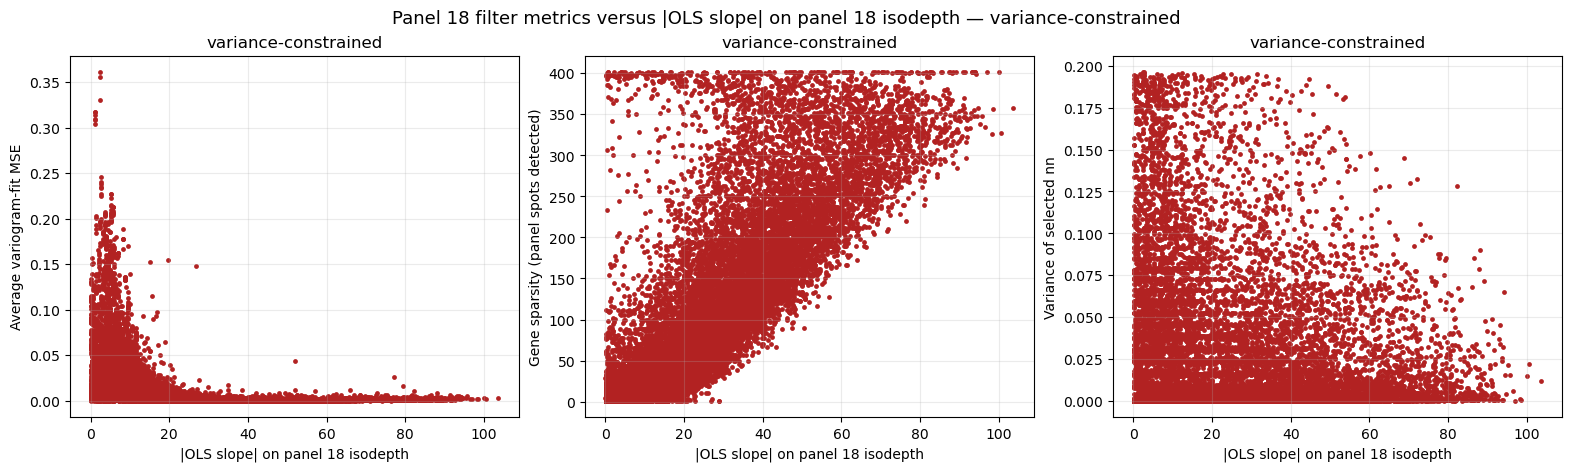

unconstrained least squares: 20708 genes.


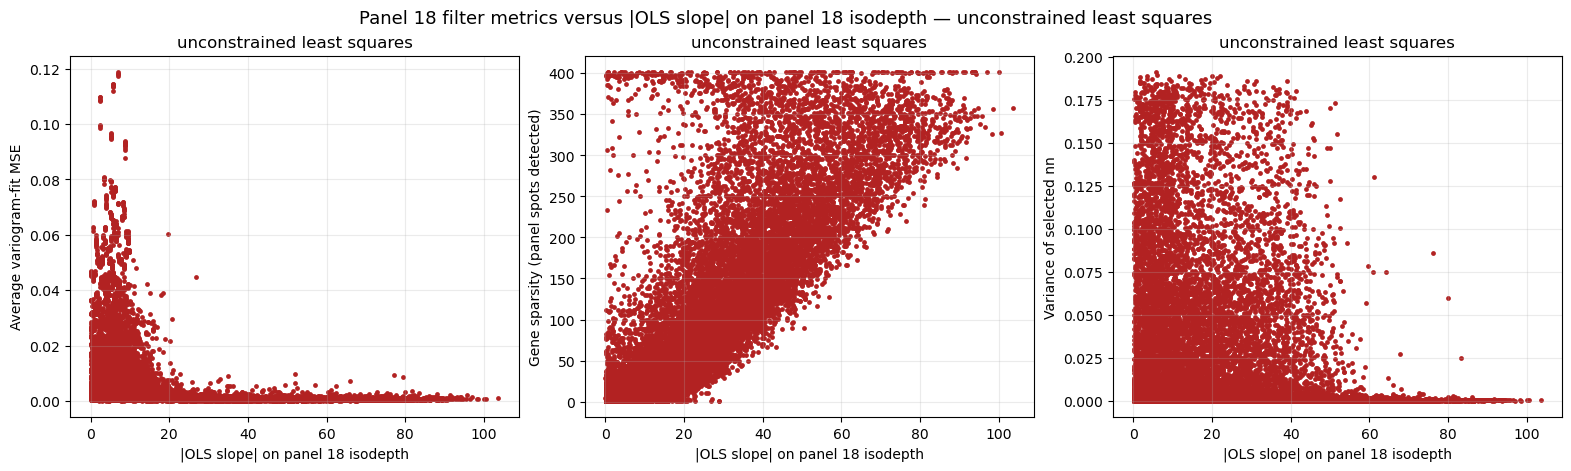

,gene,ols_slope,effect_size,fit_mse,spots_detected,average_fit_mse,smoother_choice_variance
765,MAGOH,-103.693376,103.693376,0.568312,358,0.003288,0.011715
8981,POLR2K,-100.589575,100.589575,0.593768,327,0.002323,0.021914
103,RPL22,-100.105775,100.105775,0.597667,401,0.002785,0.015089
14456,RPS27L,-98.584749,98.584749,0.609800,356,0.001810,0.000471
2092,COA6,-98.223104,98.223104,0.612658,326,0.001680,0.000810
19204,RPS21,96.955541,96.955541,0.622590,401,0.001921,0.000133


In [12]:
# Same filter metrics, with absolute OLS slope on the x-axis.
# Expression is standardized, so this slope is the change in standard deviations
# of log-CPM per unit of the saved panel 18 isodepth.
constrained_effect = plot_filter_metrics(
    stability_constrained,
    "variance-constrained",
    "effect_size",
    "|OLS slope| on panel 18 isodepth",
)
unconstrained_effect = plot_filter_metrics(
    stability_unconstrained,
    "unconstrained least squares",
    "effect_size",
    "|OLS slope| on panel 18 isodepth",
)
display(
    constrained_effect.nlargest(N_TOP_EFFECT_GENES, "effect_size")[
        [
            "gene", "ols_slope", "effect_size", "fit_mse", "spots_detected",
            "average_fit_mse", "smoother_choice_variance",
        ]
    ]
)
